# **Step 1: Load and Explore the Dataset**

In [ ]:
# =======================
# 0. LIBS + DATA LOADER
# =======================
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
sns.set(style="whitegrid")

# ----- chemin exact après upload manuel -----
FILE_PATH = "/content/SP 500 ESG Risk Ratings.csv"

# ----- chargement -----
df_orig = pd.read_csv(FILE_PATH)

# ----- quick check -----
print("Shape :", df_orig.shape)
print("\nCols  :", df_orig.columns.tolist())
print("\nHead  :")
df_orig.head(50)

Shape : (503, 15)

Cols  : ['Symbol', 'Name', 'Address', 'Sector', 'Industry', 'Full Time Employees', 'Description', 'Total ESG Risk score', 'Environment Risk Score', 'Governance Risk Score', 'Social Risk Score', 'Controversy Level', 'Controversy Score', 'ESG Risk Percentile', 'ESG Risk Level']

Head  :


,Symbol,Name,Address,Sector,Industry,Full Time Employees,Description,Total ESG Risk score,Environment Risk Score,Governance Risk Score,Social Risk Score,Controversy Level,Controversy Score,ESG Risk Percentile,ESG Risk Level
0,ENPH,"Enphase Energy, Inc.","47281 Bayside Parkway\nFremont, CA 94538\nUnit...",Technology,Solar,"3,157","Enphase Energy, Inc., together with its subsid...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EMN,Eastman Chemical Company,"200 South Wilcox Drive\nKingsport, TN 37662\nU...",Basic Materials,Specialty Chemicals,"14,000",Eastman Chemical Company operates as a special...,25.3,12.8,6.6,5.8,Moderate Controversy Level,2.0,50th percentile,Medium
2,DPZ,Domino's Pizza Inc.,"30 Frank Lloyd Wright Drive\nAnn Arbor, MI 481...",Consumer Cyclical,Restaurants,"6,500","Domino's Pizza, Inc., through its subsidiaries...",29.2,10.6,6.3,12.2,Moderate Controversy Level,2.0,66th percentile,Medium
3,DAY,"Dayforce, Inc.","3311 East Old Shakopee Road\nMinneapolis, MN 5...",Technology,Software - Application,"9,084","Dayforce Inc., together with its subsidiaries,...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DVA,Davita Inc.,"2000 16th Street\nDenver, CO 80202\nUnited States",Healthcare,Medical Care Facilities,"70,000",DaVita Inc. provides kidney dialysis services ...,22.6,0.1,8.4,14.1,Moderate Controversy Level,2.0,38th percentile,Medium
5,DRI,"Darden Restaurants, Inc.","1000 Darden Center Drive\nOrlando, FL 32837\nU...",Consumer Cyclical,Restaurants,"187,384","Darden Restaurants, Inc., together with its su...",27.5,7.9,4.6,15.0,Moderate Controversy Level,2.0,59th percentile,Medium
6,ZTS,Zoetis Inc.,"10 Sylvan Way\nParsippany, NJ 07054\nUnited St...",Healthcare,Drug Manufacturers - Specialty & Generic,"14,100","Zoetis Inc. engages in the discovery, developm...",18.8,3.2,8.7,6.8,Moderate Controversy Level,2.0,23rd percentile,Low
7,ZBH,"Zimmer Biomet Holdings, Inc.","345 East Main Street\nWarsaw, IN 46580\nUnited...",Healthcare,Medical Devices,"18,000","Zimmer Biomet Holdings, Inc., together with it...",26.0,3.6,7.9,14.5,Moderate Controversy Level,2.0,53rd percentile,Medium
8,ZBRA,Zebra Technologies Corporation,"3 Overlook Point\nLincolnshire, IL 60069\nUnit...",Technology,Communication Equipment,"9,750","Zebra Technologies Corporation, together with ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,YUM,"Yum! Brands, Inc.","1441 Gardiner Lane\nLouisville, KY 40213\nUnit...",Consumer Cyclical,Restaurants,"35,000","Yum! Brands, Inc., together with its subsidiar...",20.1,4.5,4.1,11.4,Moderate Controversy Level,2.0,28th percentile,Medium


In [ ]:
df_orig.info()
df_orig.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Symbol                  503 non-null    object 
 1   Name                    503 non-null    object 
 2   Address                 502 non-null    object 
 3   Sector                  502 non-null    object 
 4   Industry                502 non-null    object 
 5   Full Time Employees     498 non-null    object 
 6   Description             502 non-null    object 
 7   Total ESG Risk score    430 non-null    float64
 8   Environment Risk Score  430 non-null    float64
 9   Governance Risk Score   430 non-null    float64
 10  Social Risk Score       430 non-null    float64
 11  Controversy Level       430 non-null    object 
 12  Controversy Score       403 non-null    float64
 13  ESG Risk Percentile     430 non-null    object 
 14  ESG Risk Level          430 non-null    ob

# **Step 2: Data Cleaning & Preprocessing**

In [ ]:
from sklearn.impute import KNNImputer
num_cols = ["Total ESG Risk score", "Environment Risk Score", "Governance Risk Score"]

imputer = KNNImputer(n_neighbors=5)
df_orig[num_cols] = imputer.fit_transform(df_orig[num_cols])

In [ ]:
df_orig[['City', 'State']] = df_orig['Address'].str.extract(r'([A-Za-z\s]+),\s([A-Z]{2})\s\d+')


In [ ]:
df_orig['Sector'] = df_orig['Sector'].astype('category')
df_orig['Industry'] = df_orig['Industry'].astype('category')

# **Step 3: Exploratory Data Analysis (EDA)**

> Ajouter une citation



1.**ESG** Risk Score Distribution

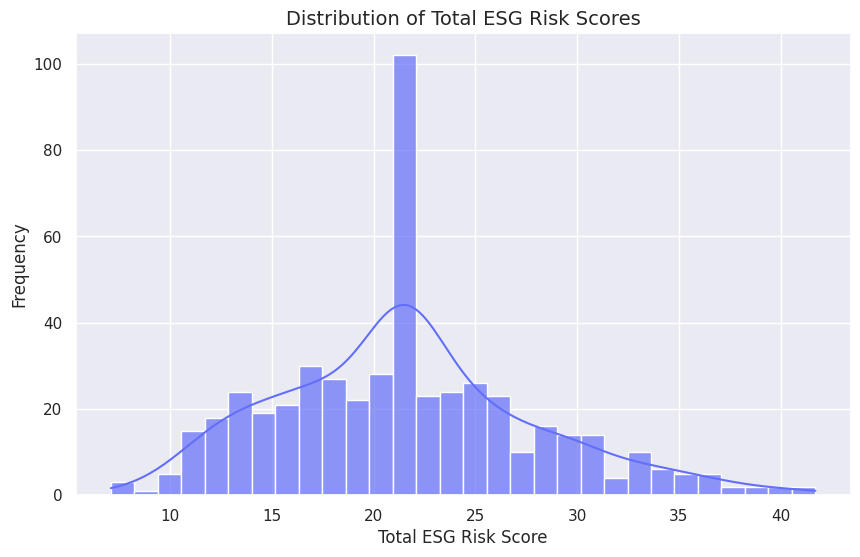

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")
plt.figure(figsize=(10, 6))
sns.histplot(df_orig["Total ESG Risk score"], bins=30, kde=True, color="#636EFA", alpha=0.7)
plt.title("Distribution of Total ESG Risk Scores", fontsize=14)
plt.xlabel("Total ESG Risk Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()

In [ ]:
import plotly.express as px

fig = px.histogram(df_orig, x="Total ESG Risk score", nbins=30, marginal="box", opacity=0.7,
                   title="Distribution of Total ESG Risk Scores", color_discrete_sequence=["#636EFA"])
fig.update_layout(bargap=0.1, template="plotly_dark")
fig.show()

 What this shows:

✔️ Most companies have moderate ESG risk.

✔️ A few companies have very high or very low risks.

**Top 10 Companies with Highest ESG Risk**

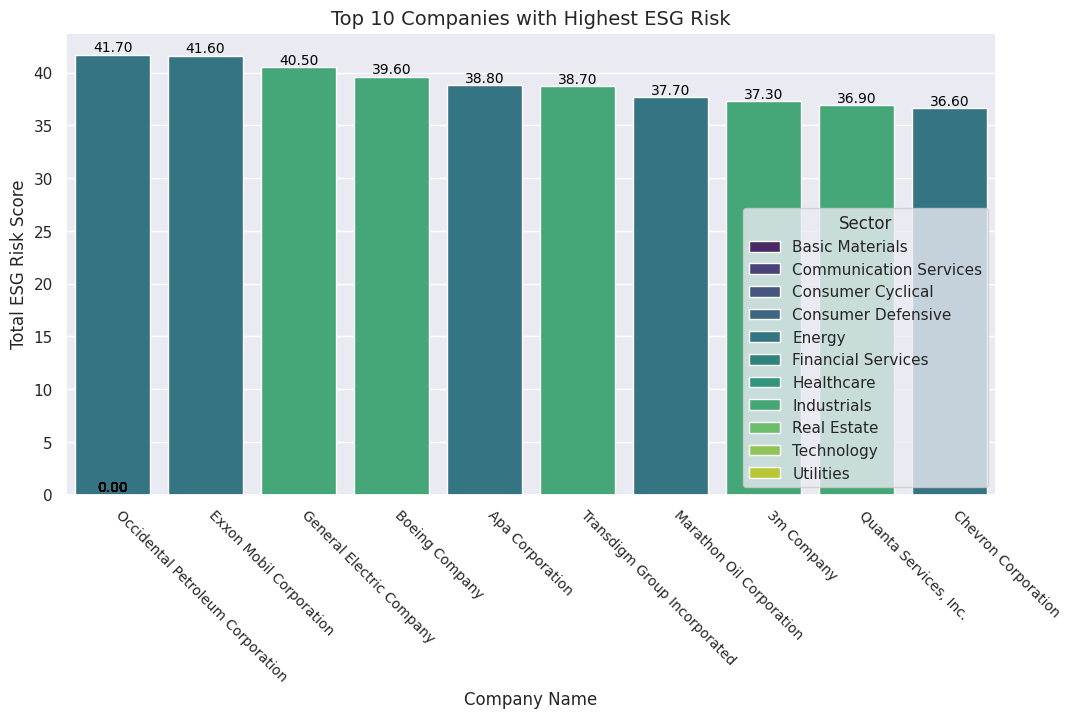

In [ ]:
top_risk_companies = df_orig.nlargest(10, "Total ESG Risk score")
sns.set_style("darkgrid")
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=top_risk_companies, x="Name", y="Total ESG Risk score", hue="Sector", palette="viridis")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10, color="black")
plt.xticks(rotation=-45, ha="left", fontsize=10)
plt.xlabel("Company Name", fontsize=12)
plt.ylabel("Total ESG Risk Score", fontsize=12)
plt.title("Top 10 Companies with Highest ESG Risk", fontsize=14)
plt.legend(title="Sector")
plt.show()

In [ ]:
top_risk_companies = df_orig.nlargest(10, "Total ESG Risk score")

fig = px.bar(top_risk_companies, x="Name", y="Total ESG Risk score", color="Sector",
             title="Top 10 Companies with Highest ESG Risk", text="Total ESG Risk score")

fig.update_layout(template="plotly_dark", xaxis_tickangle=-45)
fig.show()

**Environment vs. Governance Risk (Bubble Chart)**

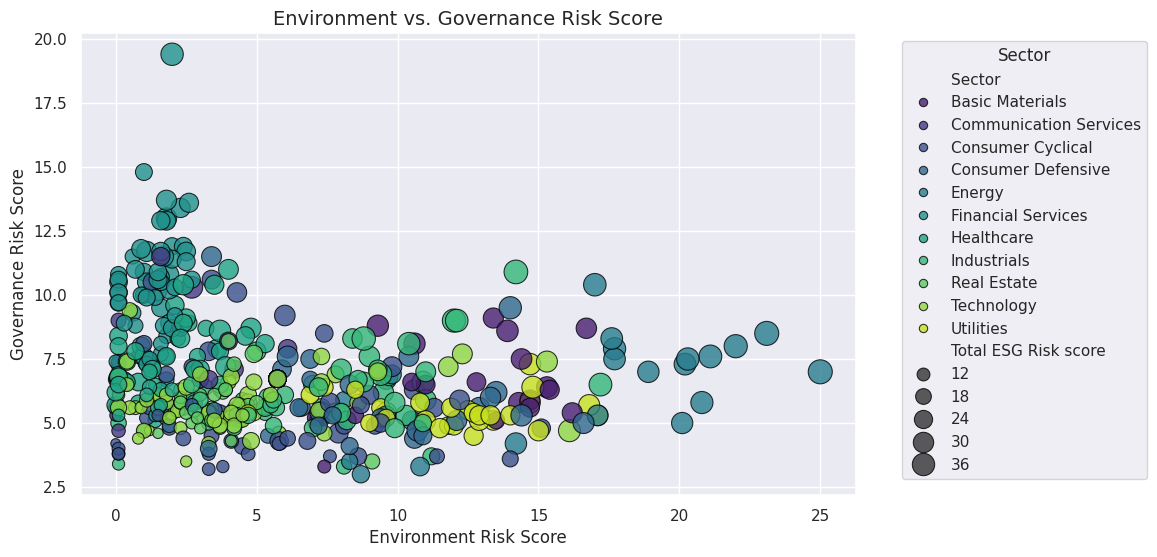

In [ ]:
sns.set_style("darkgrid")
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(data=df_orig,
                          x="Environment Risk Score",
                          y="Governance Risk Score",
                          size="Total ESG Risk score",
                          hue="Sector",
                          sizes=(50, 300),
                          alpha=0.8,
                          palette="viridis", edgecolor="black")
plt.title("Environment vs. Governance Risk Score", fontsize=14)
plt.xlabel("Environment Risk Score", fontsize=12)
plt.ylabel("Governance Risk Score", fontsize=12)
plt.legend(title="Sector", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

In [ ]:
fig = px.scatter(df_orig, x="Environment Risk Score", y="Governance Risk Score",
                 size="Total ESG Risk score", color="Sector", hover_name="Name",
                 title="Environment vs. Governance Risk Score",
                 color_continuous_scale="Viridis", opacity=0.8)

fig.update_layout(template="plotly_dark")
fig.show()

**Clustering Companies Based on ESG Scores (3D Scatter Plot)**

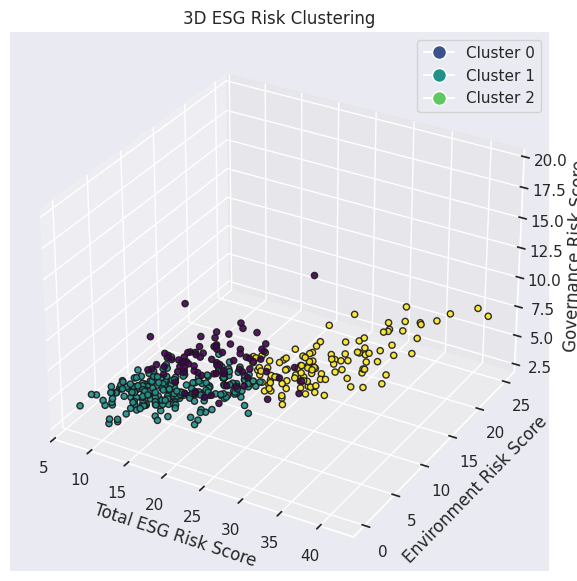

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
scaler = StandardScaler()
df_orig_scaled = scaler.fit_transform(df_orig[['Total ESG Risk score', 'Environment Risk Score', 'Governance Risk Score']])
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_orig['Cluster'] = kmeans.fit_predict(df_orig_scaled)
colors = sns.color_palette("viridis", n_colors=3)
df_orig['Cluster_Color'] = df_orig['Cluster'].map({0: colors[0], 1: colors[1], 2: colors[2]})
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(df_orig["Total ESG Risk score"], df_orig["Environment Risk Score"], df_orig["Governance Risk Score"],
                     c=df_orig['Cluster'], cmap="viridis", edgecolors="k", alpha=0.9)
ax.set_xlabel("Total ESG Risk Score")
ax.set_ylabel("Environment Risk Score")
ax.set_zlabel("Governance Risk Score")
ax.set_title("3D ESG Risk Clustering")
legend_labels = [f"Cluster {i}" for i in range(3)]
scatter_legend = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors[i], markersize=10) for i in range(3)]
ax.legend(scatter_legend, legend_labels, loc="best")
plt.show()

# **Step 4: Sector-Wise ESG Risk Analysis**

Which sectors have the highest ESG risks?

/tmp/ipython-input-4045870937.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipython-input-4045870937.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




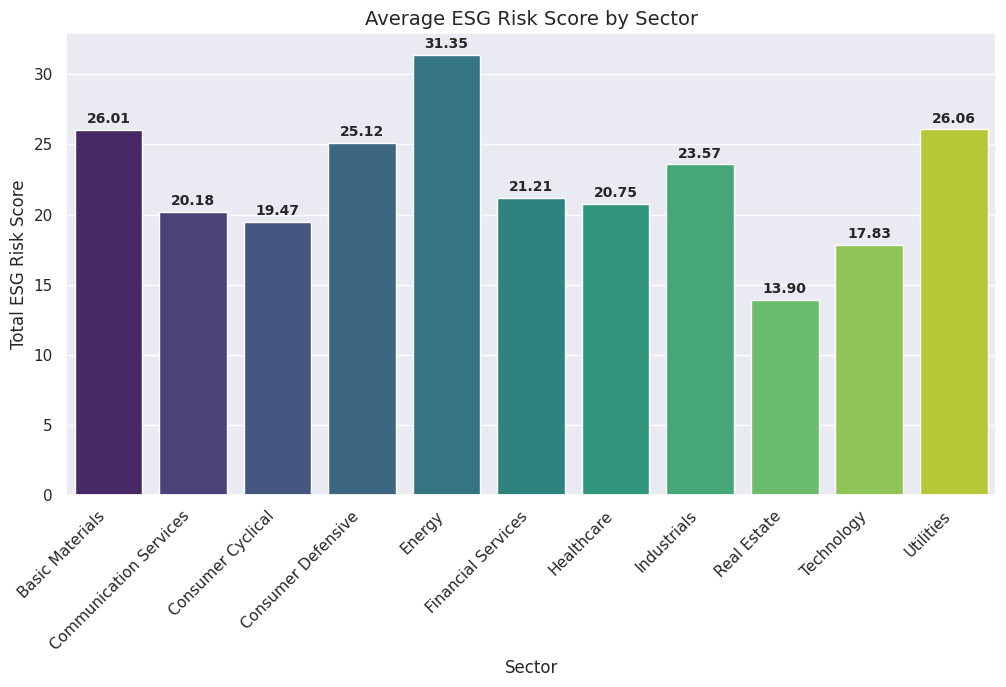

In [ ]:
sector_esg = df_orig.groupby("Sector")[["Total ESG Risk score", "Environment Risk Score", "Governance Risk Score"]].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=sector_esg, x="Sector", y="Total ESG Risk score", palette="viridis")
for index, value in enumerate(sector_esg["Total ESG Risk score"]):
    plt.text(index, value + 0.5, f"{value:.2f}", ha="center", fontsize=10, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.title("Average ESG Risk Score by Sector", fontsize=14)
plt.xlabel("Sector", fontsize=12)
plt.ylabel("Total ESG Risk Score", fontsize=12)
plt.show()

In [ ]:
sector_esg = df_orig.groupby("Sector")[["Total ESG Risk score", "Environment Risk Score", "Governance Risk Score"]].mean().reset_index()

import plotly.express as px

fig = px.bar(sector_esg, x="Sector", y="Total ESG Risk score", color="Sector",
             title="Average ESG Risk Score by Sector", text="Total ESG Risk score")

fig.update_layout(template="plotly_dark", xaxis_tickangle=-45)
fig.show()

/tmp/ipython-input-3350542501.py:1: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



🔹 Findings:

✔️ Some sectors, like Energy and Basic Materials have higher ESG risks.

✔️ Real Estate and Consumer Defensive have lower ESG risks.

# Box Plot of ESG Risk Scores by Sector

/tmp/ipython-input-2633347769.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




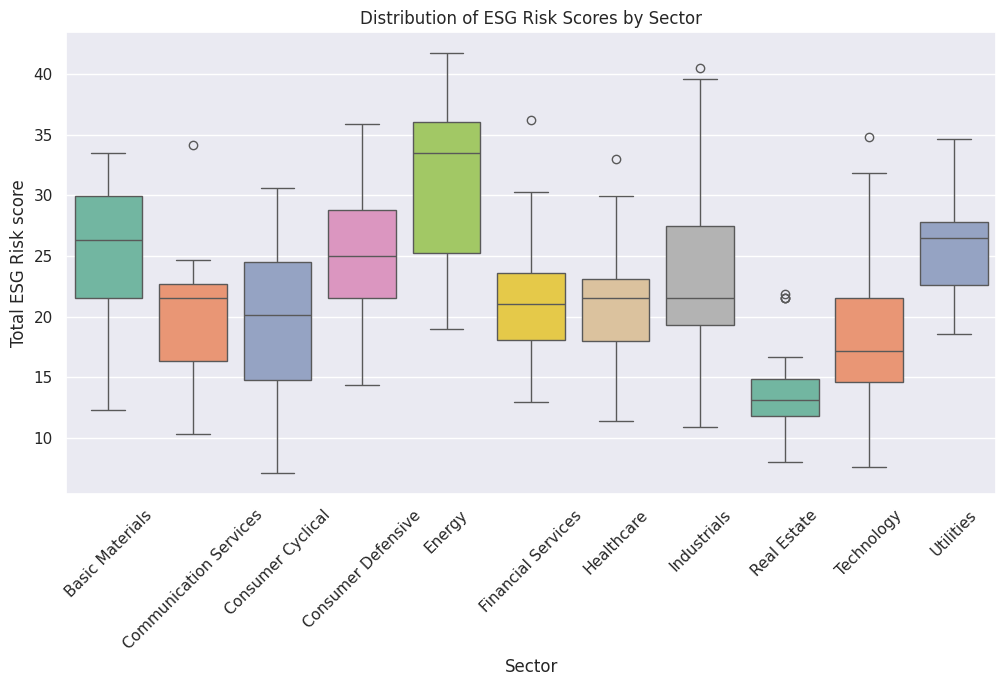

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_orig, x="Sector", y="Total ESG Risk score", palette="Set2")
plt.xticks(rotation=45)
plt.title("Distribution of ESG Risk Scores by Sector")
plt.show()

# **Step 5: Hierarchical Clustering for ESG Risk Segmentation**

In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

X = df_orig[["Total ESG Risk score", "Environment Risk Score", "Governance Risk Score"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**Find the Optimal Number of Clusters Using Silhouette Score**
Silhouette Score for different cluster numbers and choose the best one.

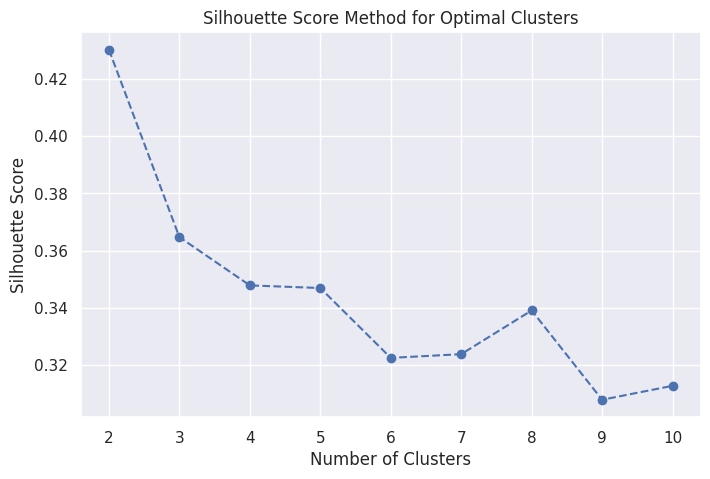

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import numpy as np

silhouette_scores = []
for k in range(2, 11):
    # Replaced 'affinity' with 'metric' as 'affinity' is deprecated/removed in newer scikit-learn versions.
    hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = hc.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Method for Optimal Clusters")
plt.show()

# Apply Hierarchical Clustering

In [ ]:
from sklearn.cluster import AgglomerativeClustering

n_clusters = 4
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
df_orig["Cluster"] = hc.fit_predict(X_scaled)

# Visualize the Clusters

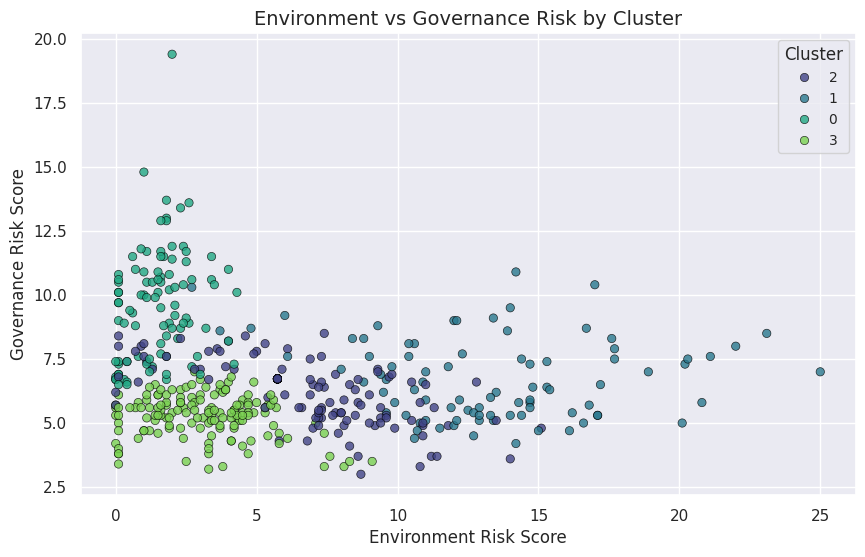

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_orig, x="Environment Risk Score", y="Governance Risk Score", hue=df_orig["Cluster"].astype(str),
                palette="viridis", alpha=0.8, edgecolor="black")
plt.title("Environment vs Governance Risk by Cluster", fontsize=14)
plt.xlabel("Environment Risk Score", fontsize=12)
plt.ylabel("Governance Risk Score", fontsize=12)
plt.legend(title="Cluster", fontsize=10)
plt.show()

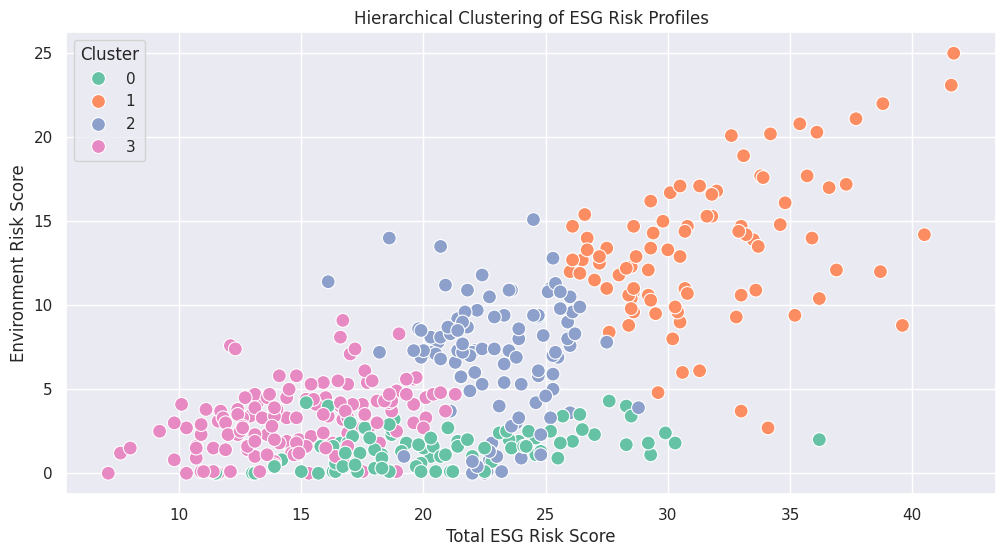

In [ ]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_orig, x="Total ESG Risk score", y="Environment Risk Score",
                hue=df_orig["Cluster"], palette="Set2", s=100)
plt.title("Hierarchical Clustering of ESG Risk Profiles")
plt.xlabel("Total ESG Risk Score")
plt.ylabel("Environment Risk Score")
plt.legend(title="Cluster")
plt.show()

# **Step 6: Analyzing ESG Clusters**

Summary of Cluster Characteristics

🔹 Cluster 0 (Low ESG Risk): Companies with strong ESG practices and low environmental/governance risks.
🔹 Cluster 1 (Moderate ESG Risk): Companies with some risks but balanced ESG performance.
🔹 Cluster 2 (High ESG Risk): Companies facing serious ESG concerns, particularly in governance or environmental issues.
🔹 Cluster 3 (Extreme ESG Risk): The most at-risk companies, often from industries like Oil & Gas, Mining, and Heavy Manufacturing.

In [ ]:
cluster_summary = df_orig.groupby("Cluster")[["Total ESG Risk score", "Environment Risk Score", "Governance Risk Score"]].mean().reset_index()
print(cluster_summary)

   Cluster  Total ESG Risk score  Environment Risk Score  \
0        0             20.906316                1.514737   
1        1             31.505747               13.291954   
2        2             22.419668                6.430131   
3        3             14.886207                3.138621   

   Governance Risk Score  
0               9.644211  
1               6.701149  
2               6.359849  
3               5.270345  


Sector Distribution Across Clusters

Energy & Mining → High environmental risk (carbon emissions, pollution).

Finance & Real Estate → Governance concerns (transparency, regulatory issues).

Technology → Privacy, data security, and ethical AI concerns.

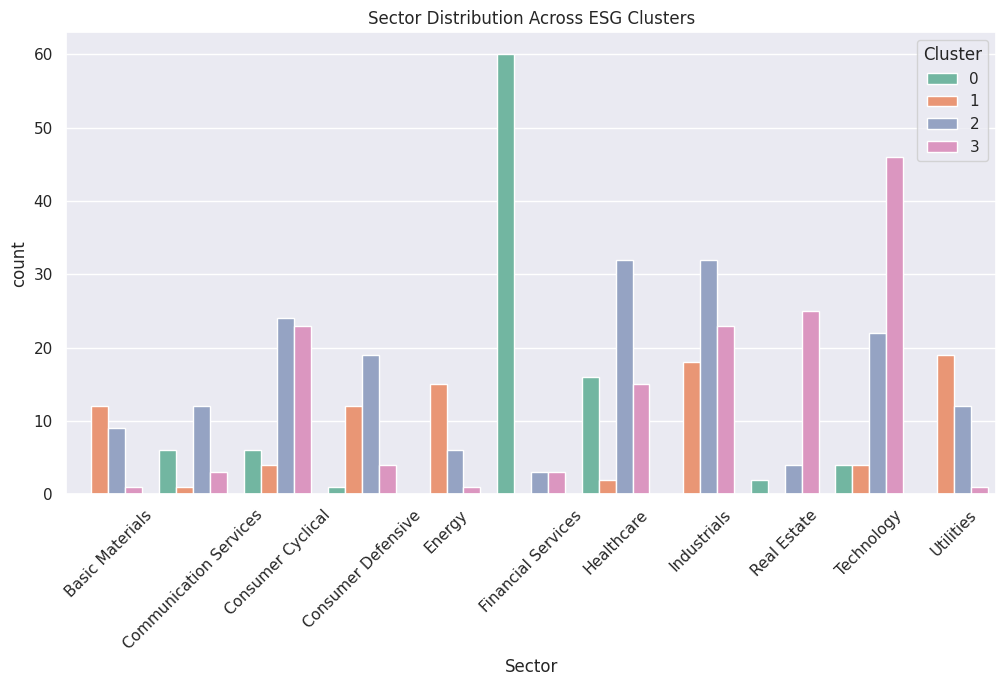

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_orig, x="Sector", hue="Cluster", palette="Set2")
plt.xticks(rotation=45)
plt.title("Sector Distribution Across ESG Clusters")
plt.legend(title="Cluster")
plt.show()

Top 5 Companies with the Highest ESG Risk

🌱 Environmental Risk (Sustainability Practices)

✅ Reduce Carbon Footprint → Invest in renewable energy, carbon offset programs.

✅ Improve Waste Management → Reduce industrial waste, improve recycling policies.

✅ Transparency in Climate Impact → Report carbon emissions, set clear sustainability goals.

📜 Governance Risk (Ethical Business Practices)

✅ Stronger Board Oversight → More independent directors, stronger compliance measures.

✅ Enhanced Data Security → Ensure cybersecurity, protect customer data.

✅ Ethical AI Practices → Avoid bias in algorithms, improve transparency in decision-making.

In [ ]:
high_risk_companies = df_orig.nlargest(5, "Total ESG Risk score")[["Name", "Sector", "Total ESG Risk score", "Cluster"]]
print(high_risk_companies)

                                 Name       Sector  Total ESG Risk score  \
166  Occidental Petroleum Corporation       Energy                  41.7   
324           Exxon Mobil Corporation       Energy                  41.6   
297          General Electric Company  Industrials                  40.5   
434                    Boeing Company  Industrials                  39.6   
465                   Apa Corporation       Energy                  38.8   

     Cluster  
166        1  
324        1  
297        1  
434        1  
465        1  


**Scatter Plot: Environment vs Governance Risk (With Clusters)**

In [ ]:
import plotly.express as px

fig = px.scatter(df_orig, x="Environment Risk Score", y="Governance Risk Score",
                 color=df_orig["Cluster"].astype(str), hover_name="Name",
                 title="Environment vs Governance Risk by Cluster",
                 opacity=0.8, template="plotly_dark")

fig.show()

**Prepare the Data for Prediction**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

features = ["Sector", "Industry", "Environment Risk Score", "Governance Risk Score"]
target = "Total ESG Risk score"

df_encoded = df_orig.copy()
label_encoders = {}
for col in ["Sector", "Industry"]:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

X = df_encoded[features]
y = df_encoded[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



```
# Ce texte est au format code
```

**Train & Evaluate XGBoost Model**

In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error

xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
print(f"XGBoost Mean Absolute Error: {mae_xgb:.4f}")

XGBoost Mean Absolute Error: 2.0789


**Train & Evaluate LightGBM Model**

In [ ]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

lgb_model = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
lgb_model.fit(X_train, y_train)
y_pred_lgb = lgb_model.predict(X_test)
mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
print(f"LightGBM Mean Absolute Error: {mae_lgb:.4f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000280 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 224
[LightGBM] [Info] Number of data points in the train set: 402, number of used features: 4
[LightGBM] [Info] Start training from score 21.484386
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

**Compare Model Performances**

In [ ]:
print(f"Random Forest MAE: 2.04")
print(f"XGBoost MAE: {mae_xgb:.4f}")
print(f"LightGBM MAE: {mae_lgb:.4f}")

Random Forest MAE: 2.04
XGBoost MAE: 2.0789
LightGBM MAE: 2.0999


# **Partie II**

## **1.Importation des donnés**

In [ ]:
import yfinance as yf
import pandas as pd

# ESG companies from low-risk sectors
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]

# Download 5 years of daily historical data
data = yf.download(tickers, period="5y", interval="1d")
data.tail()

/tmp/ipython-input-3815553137.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")
[*********************100%***********************]  5 of 5 completed


Price            Close                                                  \
Ticker            AAPL         DIS         DPZ         PLD         UNH   
Date                                                                     
2025-11-17  267.459991  105.690002  404.630005  123.519997  320.519989   
2025-11-18  267.440002  106.279999  403.339996  123.800003  313.579987   
2025-11-19  268.559998  104.669998  399.670013  122.400002  309.089996   
2025-11-20  266.250000  102.699997  397.209991  123.120003  311.540009   
2025-11-21  271.489990  104.279999  407.399994  125.790001  319.970001   

Price             High                                                  ...  \
Ticker            AAPL         DIS         DPZ         PLD         UNH  ...   
Date                                                                    ...   
2025-11-17  270.489990  107.669998  411.410004  124.690002  327.880005  ...   
2025-11-18  270.709991  107.080002  408.000000  124.250000  317.500000  ...   
2025-11-19  272.209991  107.589996  405.350006  124.269997  315.000000  ...   
2025-11-20  275.429993  105.800003  403.000000  125.550003  314.750000  ...   
2025-11-21  273.329987  104.779999  413.649994  126.500000  323.839996  ...   

Price             Open                                                  \
Ticker            AAPL         DIS         DPZ         PLD         UNH   
Date                                                                     
2025-11-17  268.820007  105.750000  410.600006  123.529999  320.600006   
2025-11-18  269.989990  105.099998  403.410004  123.300003  317.010010   
2025-11-19  265.529999  106.080002  403.450012  123.800003  313.929993   
2025-11-20  270.829987  105.370003  399.959991  123.650002  310.809998   
2025-11-21  265.950012  103.480003  398.670013  123.760002  311.910004   

Price         Volume                                      
Ticker          AAPL       DIS     DPZ      PLD      UNH  
Date                                                      
2025-11-17  45018300  12296400  500600  3111000  6485400  
2025-11-18  45677300  11796200  312400  6382500  9182100  
2025-11-19  40424500  12790000  326000  5119100  8181100  
2025-11-20  45823600  12609900  486500  3087200  7337600  
2025-11-21  58784100  10773900  476300  3709000  8394000  

[5 rows x 25 columns]

### **Data Preprocessing**

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1256 entries, 2020-11-23 to 2025-11-21
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   1256 non-null   float64
 1   (Close, DIS)    1256 non-null   float64
 2   (Close, DPZ)    1256 non-null   float64
 3   (Close, PLD)    1256 non-null   float64
 4   (Close, UNH)    1256 non-null   float64
 5   (High, AAPL)    1256 non-null   float64
 6   (High, DIS)     1256 non-null   float64
 7   (High, DPZ)     1256 non-null   float64
 8   (High, PLD)     1256 non-null   float64
 9   (High, UNH)     1256 non-null   float64
 10  (Low, AAPL)     1256 non-null   float64
 11  (Low, DIS)      1256 non-null   float64
 12  (Low, DPZ)      1256 non-null   float64
 13  (Low, PLD)      1256 non-null   float64
 14  (Low, UNH)      1256 non-null   float64
 15  (Open, AAPL)    1256 non-null   float64
 16  (Open, DIS)     1256 non-null   float64
 17  (Open, DPZ)    

no missing data

In [ ]:
import numpy as np
# Créer un nouveau DataFrame pour stocker la volatilité
vol_data = pd.DataFrame(index=data.index)

# Boucle pour calculer la volatilité pour chaque ticker
for t in tickers:
    df_ticker = data.xs(t, axis=1, level=1)  # extraire les colonnes du ticker
    # Retours log
    returns = np.log(df_ticker['Close'] / df_ticker['Close'].shift(1))
    # Volatilité sur 21 jours
    volatility = returns.rolling(window=21).std()
    # Ajouter la volatilité au DataFrame principal
    vol_data[t] = volatility

# Maintenant tu peux concaténer avec le DataFrame principal si tu veux
# Exemple : ajouter en multi-index
for t in tickers:
    data[('Volatility', t)] = vol_data[t]

# Vérification
display(data.tail(10))


Price            Close                                                  \
Ticker            AAPL         DIS         DPZ         PLD         UNH   
Date                                                                     
2025-11-10  269.429993  112.239998  407.589996  124.900002  321.579987   
2025-11-11  275.250000  114.849998  409.230011  126.260002  327.450012   
2025-11-12  273.470001  116.650002  403.760010  124.839996  339.059998   
2025-11-13  272.950012  107.610001  408.679993  124.000000  332.519989   
2025-11-14  272.410004  105.800003  410.160004  122.830002  321.859985   
2025-11-17  267.459991  105.690002  404.630005  123.519997  320.519989   
2025-11-18  267.440002  106.279999  403.339996  123.800003  313.579987   
2025-11-19  268.559998  104.669998  399.670013  122.400002  309.089996   
2025-11-20  266.250000  102.699997  397.209991  123.120003  311.540009   
2025-11-21  271.489990  104.279999  407.399994  125.790001  319.970001   

Price             High                                                  ...  \
Ticker            AAPL         DIS         DPZ         PLD         UNH  ...   
Date                                                                    ...   
2025-11-10  273.730011  112.790001  410.179993  125.970001  324.250000  ...   
2025-11-11  275.910004  114.970001  410.859985  126.410004  327.859985  ...   
2025-11-12  275.730011  117.089996  411.510010  126.400002  343.170013  ...   
2025-11-13  276.700012  109.360001  412.299988  124.830002  339.029999  ...   
2025-11-14  275.959991  108.730003  412.769989  125.019997  328.209991  ...   
2025-11-17  270.489990  107.669998  411.410004  124.690002  327.880005  ...   
2025-11-18  270.709991  107.080002  408.000000  124.250000  317.500000  ...   
2025-11-19  272.209991  107.589996  405.350006  124.269997  315.000000  ...   
2025-11-20  275.429993  105.800003  403.000000  125.550003  314.750000  ...   
2025-11-21  273.329987  104.779999  413.649994  126.500000  323.839996  ...   

Price         Volume                                      Volatility  \
Ticker          AAPL       DIS     DPZ      PLD       UNH        DPZ   
Date                                                                   
2025-11-10  41312400   9158700  463700  2101300   9283800   0.014020   
2025-11-11  46208300   9713300  279000  2068000   7157800   0.014010   
2025-11-12  48398000  15248700  544100  2687000  10403300   0.011221   
2025-11-13  49602800  44045400  486000  3761000   7788700   0.011183   
2025-11-14  47431300  16691400  445400  3651800   8676500   0.011228   
2025-11-17  45018300  12296400  500600  3111000   6485400   0.011570   
2025-11-18  45677300  11796200  312400  6382500   9182100   0.010875   
2025-11-19  40424500  12790000  326000  5119100   8181100   0.010926   
2025-11-20  45823600  12609900  486500  3087200   7337600   0.010463   
2025-11-21  58784100  10773900  476300  3709000   8394000   0.012118   

Price                                               
Ticker          AAPL       UNH       PLD       DIS  
Date                                                
2025-11-10  0.011702  0.014161  0.017393  0.010219  
2025-11-11  0.012226  0.014594  0.017346  0.011130  
2025-11-12  0.012448  0.016861  0.017167  0.011450  
2025-11-13  0.012526  0.017174  0.011084  0.021388  
2025-11-14  0.012315  0.018203  0.010893  0.021403  
2025-11-17  0.012797  0.018173  0.009615  0.021306  
2025-11-18  0.009815  0.017423  0.007784  0.021151  
2025-11-19  0.009838  0.017346  0.007898  0.020631  
2025-11-20  0.009261  0.017672  0.008053  0.020840  
2025-11-21  0.010052  0.019141  0.009433  0.021274  

[10 rows x 30 columns]

### **Exploratory Data Analysis**


====== DPZ Data ======


Price,Close,High,Low,Open,Volume,Volatility
Date,,,,,,
2025-11-17,404.630005,411.410004,403.149994,410.600006,500600,0.011570
2025-11-18,403.339996,408.000000,400.000000,403.410004,312400,0.010875
2025-11-19,399.670013,405.350006,399.500000,403.450012,326000,0.010926
2025-11-20,397.209991,403.000000,397.070007,399.959991,486500,0.010463
2025-11-21,407.399994,413.649994,398.170013,398.670013,476300,0.012118



------ DPZ Statistical Summary (describe) ------


Price,Close,High,Low,Open,Volume,Volatility
count,1256.000000,1256.000000,1256.000000,1256.000000,1.256000e+03,1235.000000
mean,404.196425,409.040550,399.396716,404.266686,6.063654e+05,0.017266
std,59.942014,60.457955,59.394873,59.948878,3.257233e+05,0.006224
min,279.865509,282.820098,275.993633,281.313838,1.843000e+05,0.006854
25%,359.524986,362.838868,355.228840,359.300194,4.285500e+05,0.013064
50%,405.977066,410.879990,401.306875,405.773222,5.277500e+05,0.015890
75%,452.707626,458.446069,446.482712,452.058189,6.891000e+05,0.019805
max,536.273499,539.352408,529.687995,535.845813,3.821500e+06,0.037857


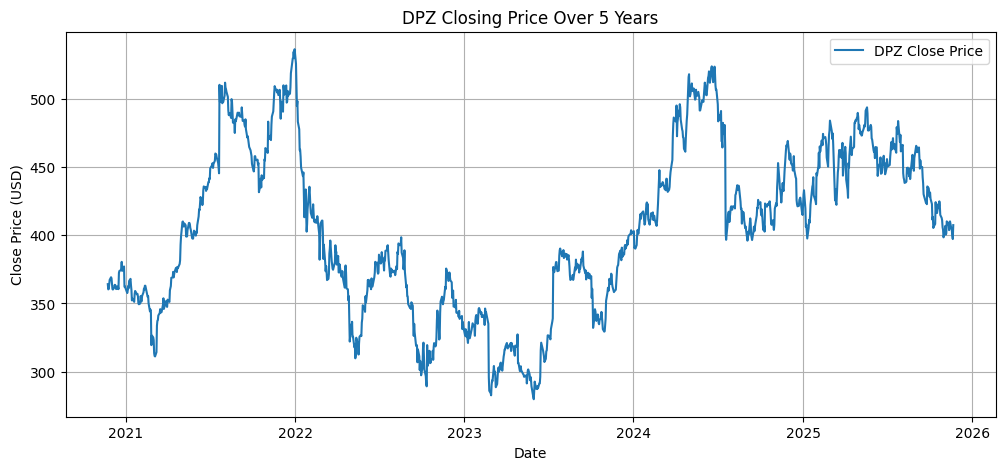

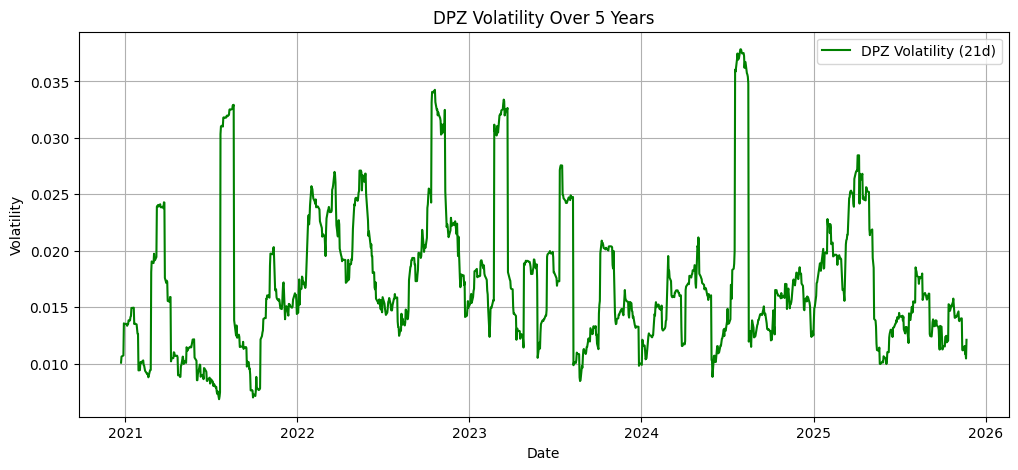


====== AAPL Data ======


Price,Close,High,Low,Open,Volume,Volatility
Date,,,,,,
2025-11-17,267.459991,270.489990,265.730011,268.820007,45018300,0.012797
2025-11-18,267.440002,270.709991,265.320007,269.989990,45677300,0.009815
2025-11-19,268.559998,272.209991,265.500000,265.529999,40424500,0.009838
2025-11-20,266.250000,275.429993,265.920013,270.829987,45823600,0.009261
2025-11-21,271.489990,273.329987,265.670013,265.950012,58784100,0.010052



------ AAPL Statistical Summary (describe) ------


Price,Close,High,Low,Open,Volume,Volatility
count,1256.000000,1256.000000,1256.000000,1256.000000,1.256000e+03,1235.000000
mean,176.295833,178.049387,174.366996,176.116765,7.116579e+07,0.016515
std,38.378208,38.616449,38.079909,38.321947,3.034792e+07,0.006554
min,110.827538,112.774451,109.600994,110.885958,2.323470e+07,0.006038
25%,145.094494,146.333998,143.310151,145.077048,4.898090e+07,0.012241
50%,170.817070,171.931656,168.682292,170.351263,6.448710e+07,0.015290
75%,205.772396,208.232107,201.690369,205.222984,8.635778e+07,0.019298
max,275.250000,277.051436,272.089996,276.721738,3.186799e+08,0.049408


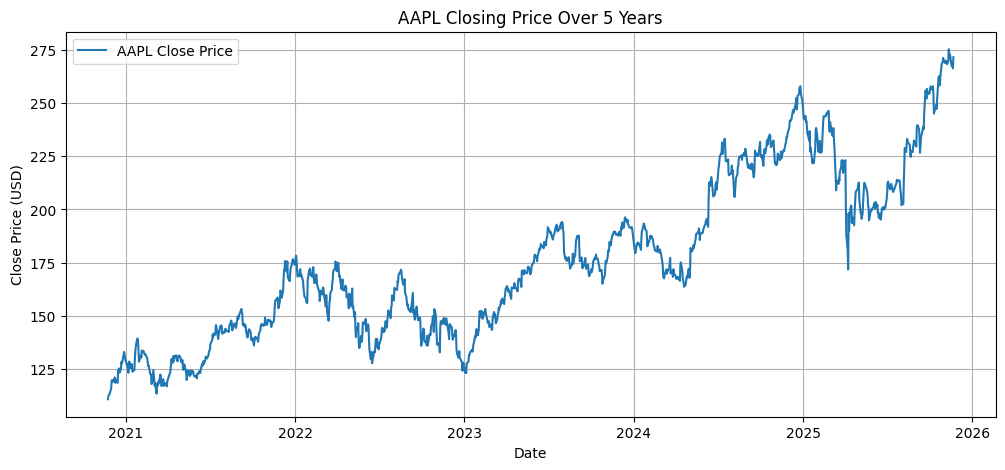

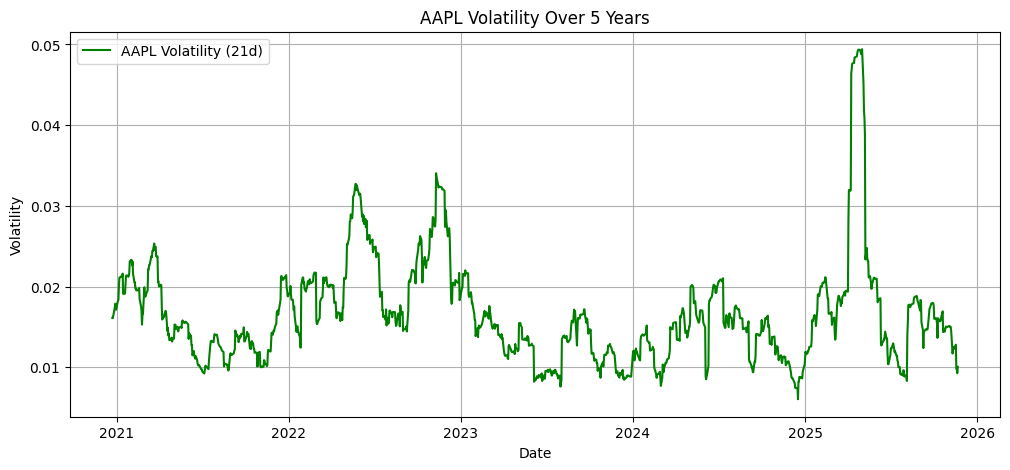


====== UNH Data ======


Price,Close,High,Low,Open,Volume,Volatility
Date,,,,,,
2025-11-17,320.519989,327.880005,319.429993,320.600006,6485400,0.018173
2025-11-18,313.579987,317.500000,308.769989,317.010010,9182100,0.017423
2025-11-19,309.089996,315.000000,304.529999,313.929993,8181100,0.017346
2025-11-20,311.540009,314.750000,310.000000,310.809998,7337600,0.017672
2025-11-21,319.970001,323.839996,311.440002,311.910004,8394000,0.019141



------ UNH Statistical Summary (describe) ------


Price,Close,High,Low,Open,Volume,Volatility
count,1256.000000,1256.000000,1256.000000,1256.000000,1.256000e+03,1235.000000
mean,447.051435,451.658485,442.411518,447.025067,4.920056e+06,0.016506
std,78.833475,79.394111,78.287696,78.889065,6.611159e+06,0.009416
min,236.279343,240.731250,233.129218,236.746395,1.135000e+06,0.005554
25%,384.784332,388.815566,381.800274,384.947183,2.519975e+06,0.011383
50%,468.372757,472.162969,462.442821,467.675470,3.114350e+06,0.014015
75%,502.136963,505.666680,496.845931,501.971352,4.567525e+06,0.018724
max,611.977844,617.341501,600.888329,606.428123,1.218492e+08,0.072163


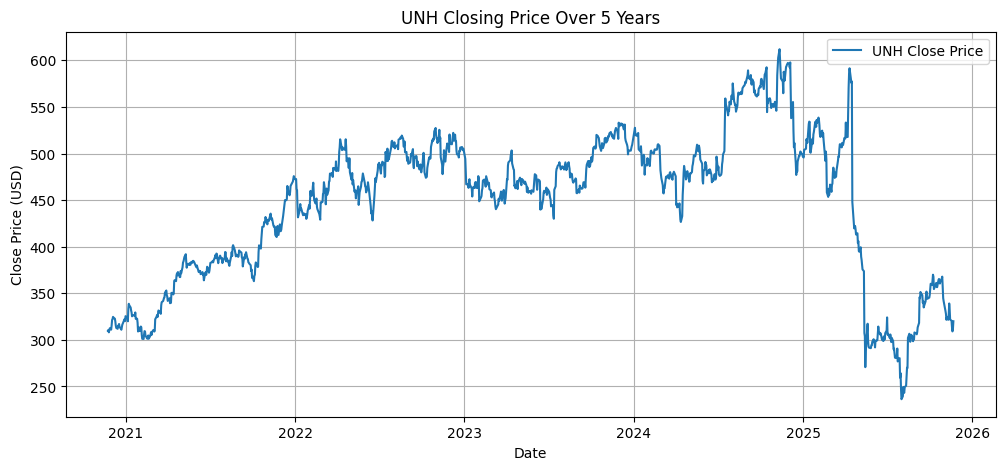

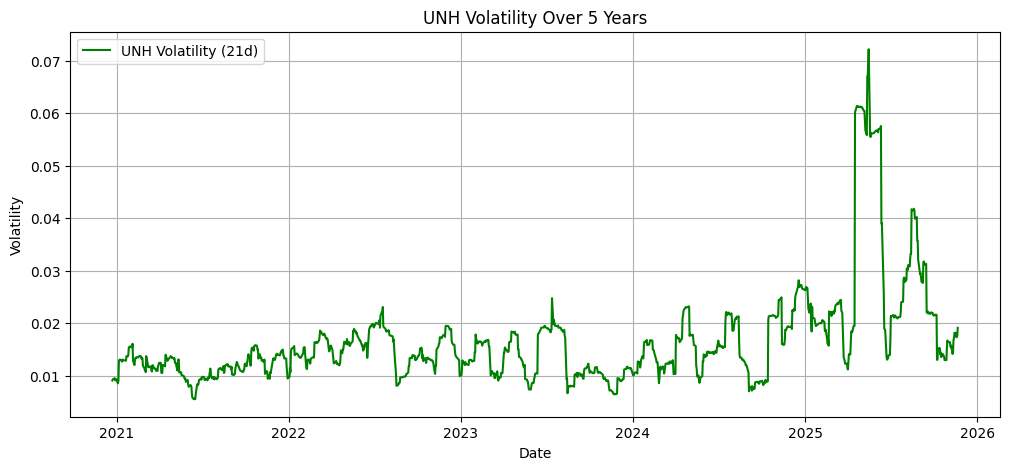


====== PLD Data ======


Price,Close,High,Low,Open,Volume,Volatility
Date,,,,,,
2025-11-17,123.519997,124.690002,122.400002,123.529999,3111000,0.009615
2025-11-18,123.800003,124.250000,122.309998,123.300003,6382500,0.007784
2025-11-19,122.400002,124.269997,121.400002,123.800003,5119100,0.007898
2025-11-20,123.120003,125.550003,122.900002,123.650002,3087200,0.008053
2025-11-21,125.790001,126.500000,122.610001,123.760002,3709000,0.009433



------ PLD Statistical Summary (describe) ------


Price,Close,High,Low,Open,Volume,Volatility
count,1256.000000,1256.000000,1256.000000,1256.000000,1.256000e+03,1235.000000
mean,112.615878,113.845382,111.341903,112.637011,3.442343e+06,0.016149
std,13.343998,13.444411,13.195528,13.347610,1.806020e+06,0.005447
min,82.272392,83.201018,81.545233,82.272395,7.140000e+05,0.006483
25%,104.433800,105.654615,103.259124,104.477070,2.401875e+06,0.012333
50%,112.633999,113.786703,111.370675,112.598009,3.043100e+06,0.015217
75%,119.009392,120.350697,117.948012,119.315167,3.933700e+06,0.018611
max,155.411072,156.785449,153.380981,156.659691,1.807210e+07,0.037841


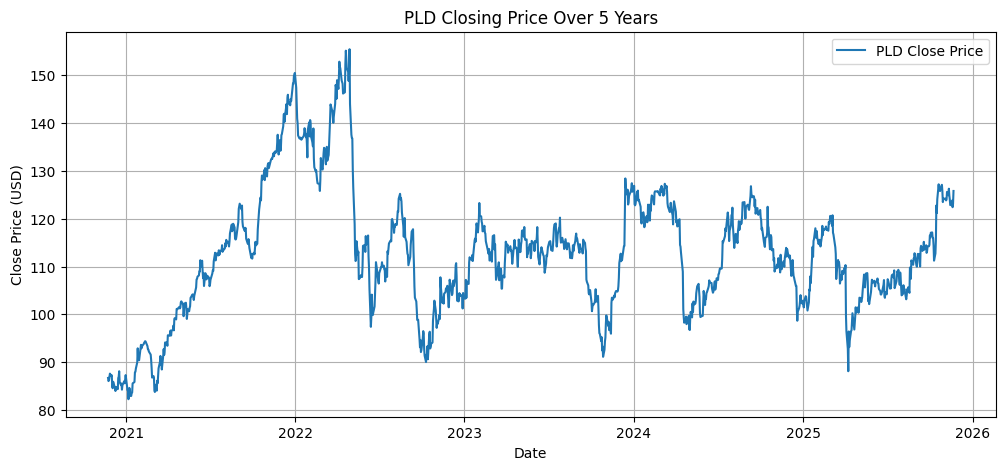

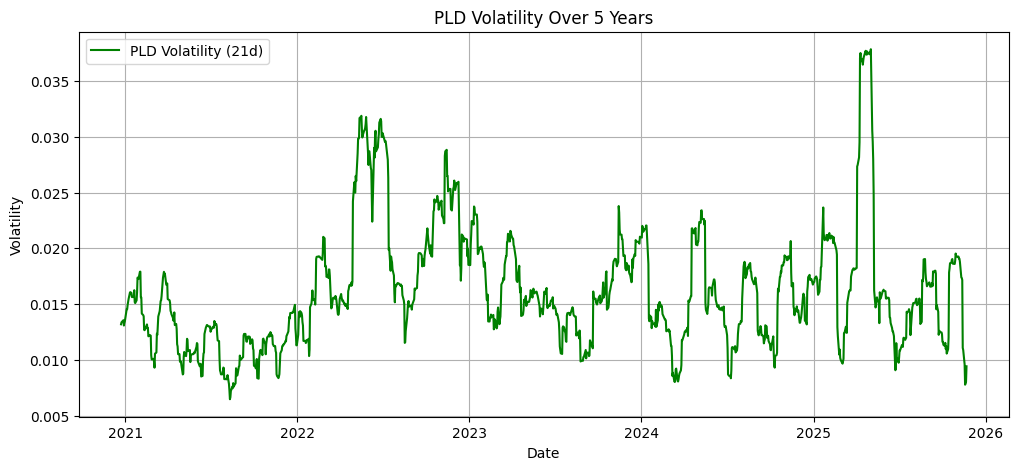


====== DIS Data ======


Price,Close,High,Low,Open,Volume,Volatility
Date,,,,,,
2025-11-17,105.690002,107.669998,105.120003,105.750000,12296400,0.021306
2025-11-18,106.279999,107.080002,105.000000,105.099998,11796200,0.021151
2025-11-19,104.669998,107.589996,104.080002,106.080002,12790000,0.020631
2025-11-20,102.699997,105.800003,102.500000,105.370003,12609900,0.020840
2025-11-21,104.279999,104.779999,102.690002,103.480003,10773900,0.021274



------ DIS Statistical Summary (describe) ------


Price,Close,High,Low,Open,Volume,Volatility
count,1256.000000,1256.000000,1256.000000,1256.000000,1.256000e+03,1235.000000
mean,118.584515,119.857157,117.312138,118.617900,1.133924e+07,0.017219
std,32.043937,32.396589,31.737986,32.122595,6.915881e+06,0.006957
min,78.019363,78.481658,77.439041,77.802965,2.475000e+06,0.007231
25%,93.914354,94.907816,92.811651,94.089614,7.664250e+06,0.011632
50%,109.066906,110.580181,108.019357,109.305690,9.649200e+06,0.015890
75%,139.723206,140.861731,137.372419,138.715014,1.267150e+07,0.021346
max,198.599213,199.691012,192.195949,196.907412,8.741070e+07,0.041834


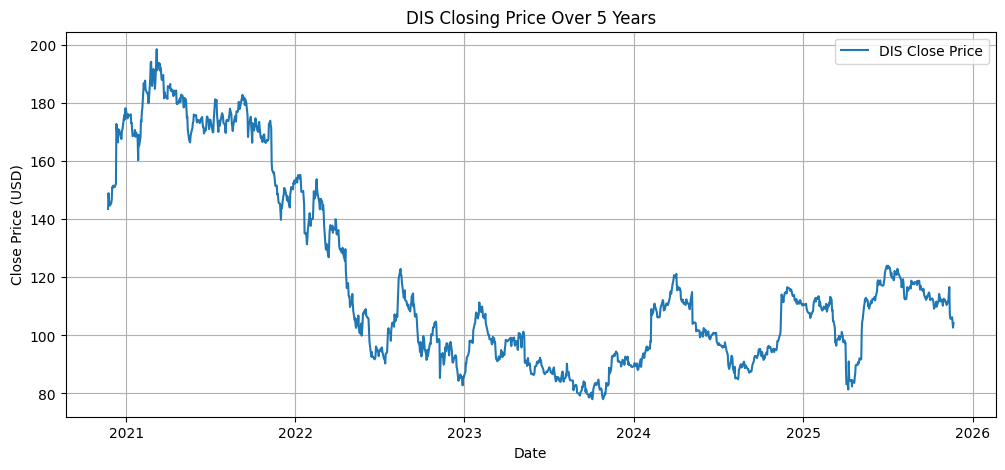

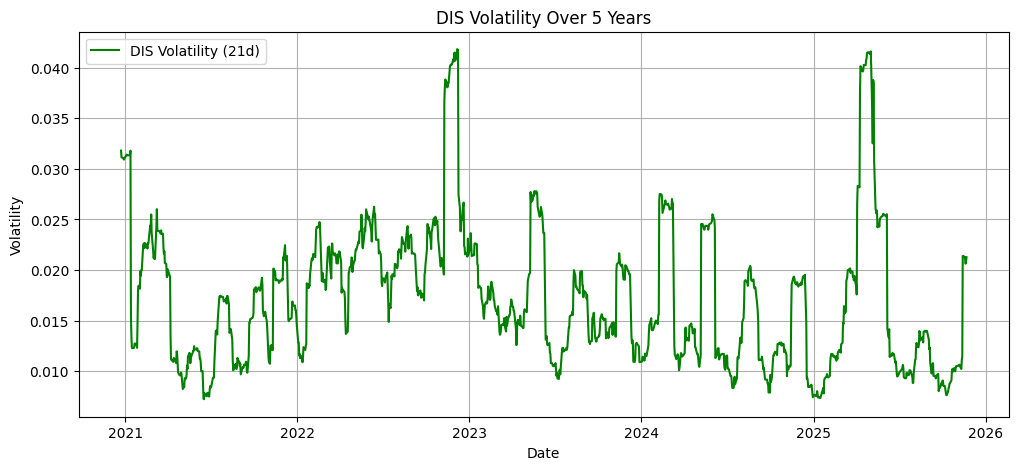

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Loop to show each ticker separately and calculate volatility
for t in tickers:
    print(f"\n====== {t} Data ======")
    df_ticker = data.xs(t, axis=1, level=1)  # extract columns for ticker
    display(df_ticker.tail())
    print(f"\n------ {t} Statistical Summary (describe) ------")
    display(df_ticker.describe())

    # ---------------- Plot Close price ----------------
    plt.figure(figsize=(12,5))
    plt.plot(df_ticker.index, df_ticker['Close'], label=f'{t} Close Price')
    plt.title(f'{t} Closing Price Over 5 Years')
    plt.xlabel('Date')
    plt.ylabel('Close Price (USD)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # ---------------- Plot Volatility ----------------
    plt.figure(figsize=(12,5))
    plt.plot(df_ticker.index, df_ticker['Volatility'], label=f'{t} Volatility (21d)', color='green')
    plt.title(f'{t} Volatility Over 5 Years')
    plt.xlabel('Date')
    plt.ylabel('Volatility')
    plt.legend()
    plt.grid(True)
    plt.show()



we have only 1255  records per table in 5 years because weekends are not included

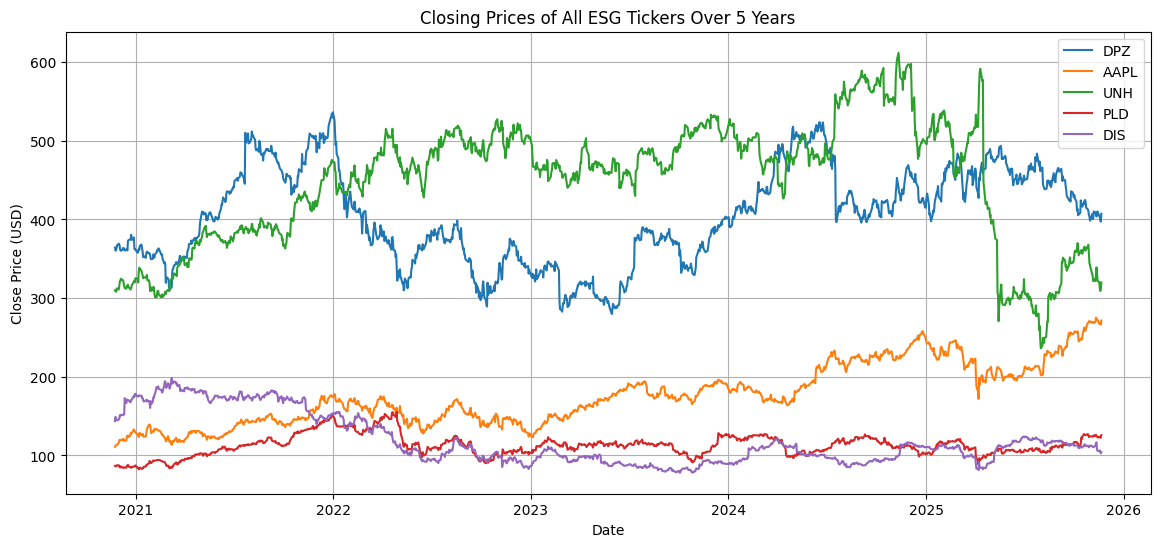

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

for t in tickers:
    df_ticker = data.xs(t, axis=1, level=1)
    plt.plot(df_ticker.index, df_ticker['Close'], label=t)

plt.title('Closing Prices of All ESG Tickers Over 5 Years')
plt.xlabel('Date')
plt.ylabel('Close Price (USD)')
plt.legend()
plt.grid(True)
plt.show()


### **Modeling**

In [ ]:
#Préparer features et labels pour prédiction
#Créer le label Volatility_Next
for t in tickers:
    data[('Volatility_Next', t)] = data[('Volatility', t)].shift(-1)
data_clean = data.dropna()

# Assure-toi que data a déjà Volatility et Volatility_Next
feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volatility', 'Returns']

# Ajouter Returns pour chaque ticker
for t in tickers:
    df_ticker = data.xs(t, axis=1, level=1)
    returns = np.log(df_ticker['Close'] / df_ticker['Close'].shift(1))
    data[('Returns', t)] = returns

# Nettoyer les NaN après calcul des retours
data_clean = data.dropna()

# Créer X et y pour chaque ticker
X_dict = {}
y_dict = {}

for t in tickers:
    # Features
    X_dict[t] = data_clean[[ (col, t) for col in feature_cols ]]
    # Label = volatilité du jour suivant
    y_dict[t] = data_clean[('Volatility_Next', t)]

# Exemple pour DPZ
X_DPZ = X_dict['DPZ']
y_DPZ = y_dict['DPZ']

display(X_DPZ.tail())
display(y_DPZ.tail())


Price,Open,High,Low,Close,Volume,Volatility,Returns
Ticker,DPZ,DPZ,DPZ,DPZ,DPZ,DPZ,DPZ
Date,,,,,,,
2025-11-14,409.410004,412.769989,405.209991,410.160004,445400,0.011228,0.003615
2025-11-17,410.600006,411.410004,403.149994,404.630005,500600,0.011570,-0.013574
2025-11-18,403.410004,408.000000,400.000000,403.339996,312400,0.010875,-0.003193
2025-11-19,403.450012,405.350006,399.500000,399.670013,326000,0.010926,-0.009141
2025-11-20,399.959991,403.000000,397.070007,397.209991,486500,0.010463,-0.006174


,Volatility_Next
,DPZ
Date,
2025-11-14,0.011570
2025-11-17,0.010875
2025-11-18,0.010926
2025-11-19,0.010463
2025-11-20,0.012118


### **Random Forest**

RMSE: 0.00122
MAE: 0.00078


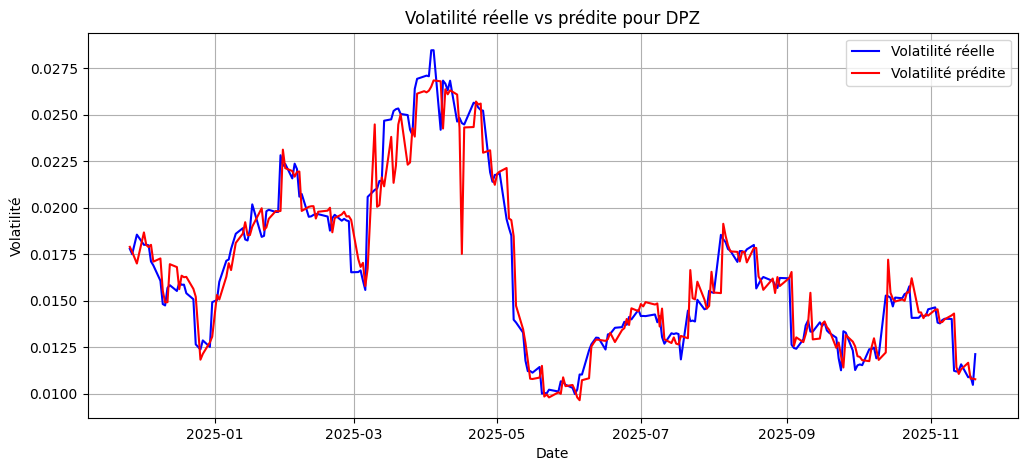

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Séparer train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_DPZ, y_DPZ, test_size=0.2, shuffle=False
)

# Créer le modèle
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Entraîner
rf_model.fit(X_train, y_train)

# Prédire
y_pred = rf_model.predict(X_test)

# Évaluer
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"RMSE: {rmse:.5f}")
print(f"MAE: {mae:.5f}")

# Optionnel : visualiser volatilité réelle vs prédite
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(y_test.index, y_test, label='Volatilité réelle', color='blue')
plt.plot(y_test.index, y_pred, label='Volatilité prédite', color='red')
plt.title('Volatilité réelle vs prédite pour DPZ')
plt.xlabel('Date')
plt.ylabel('Volatilité')
plt.legend()
plt.grid(True)
plt.show()


/tmp/ipython-input-1842592958.py:14: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-1842592958.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-1842592958.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(21).


========== DPZ ==========
RMSE = 0.033466
MAE  = 0.022464


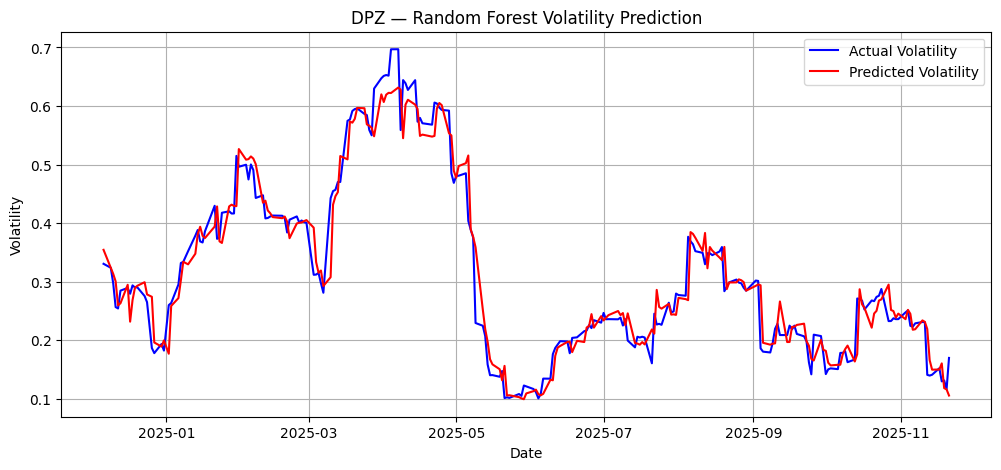


========== AAPL ==========


/tmp/ipython-input-1842592958.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-1842592958.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(21).std()
/tmp/ipython-input-1842592958.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

RMSE = 0.118387
MAE  = 0.052777


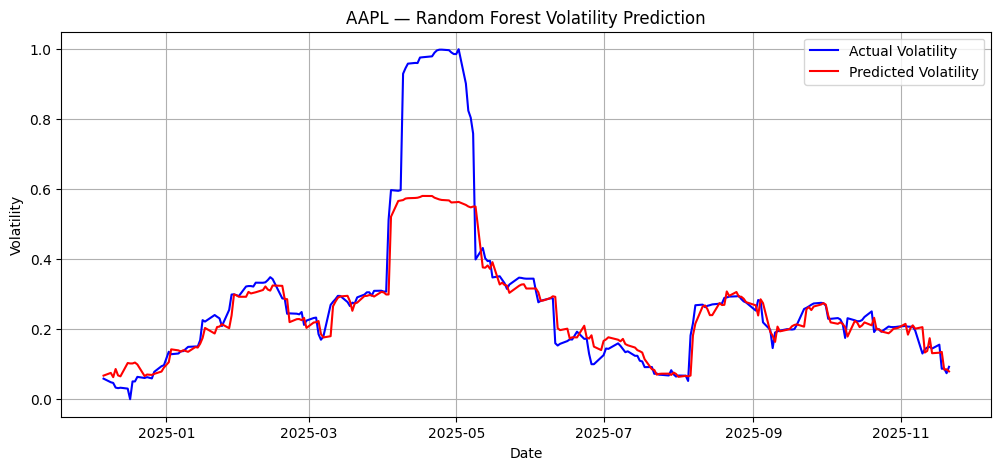


========== UNH ==========


/tmp/ipython-input-1842592958.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-1842592958.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(21).std()
/tmp/ipython-input-1842592958.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

RMSE = 0.251308
MAE  = 0.146844


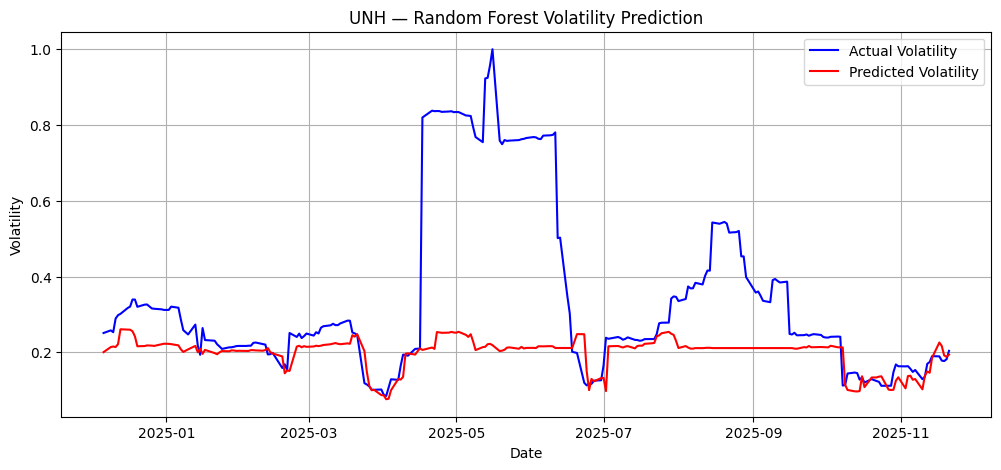


========== PLD ==========


/tmp/ipython-input-1842592958.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-1842592958.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(21).std()
/tmp/ipython-input-1842592958.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

RMSE = 0.079742
MAE  = 0.040945


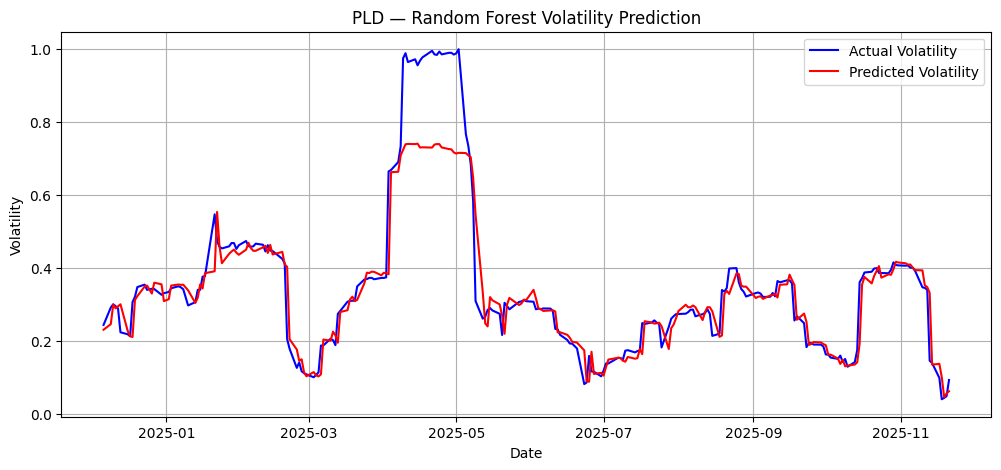


========== DIS ==========


/tmp/ipython-input-1842592958.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-1842592958.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(21).std()
/tmp/ipython-input-1842592958.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html

RMSE = 0.051615
MAE  = 0.027496


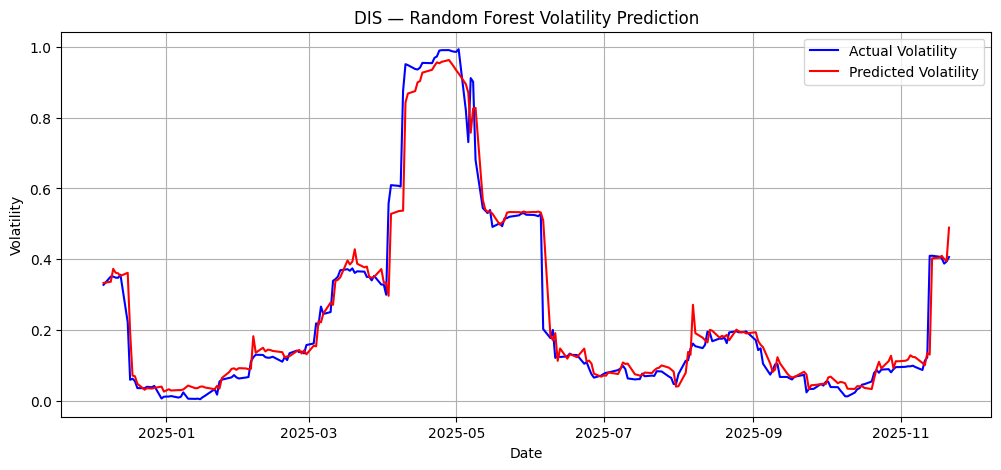


====== MODEL PERFORMANCE ======
  Ticker      RMSE       MAE
0    DPZ  0.033466  0.022464
1   AAPL  0.118387  0.052777
2    UNH  0.251308  0.146844
3    PLD  0.079742  0.040945
4    DIS  0.051615  0.027496


In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# ------------------------------
# 1. Download ALL tickers
# ------------------------------
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
data = yf.download(tickers, period="5y", interval="1d")

# Features used
features = ["Open", "High", "Low", "Close", "Volume"]

# List to store performance
results = []

# ------------------------------
# 2. Function to build dataset (window = 30 days)
# ------------------------------
def make_windows(df, window=30):
    X, y = [], []
    for i in range(window, len(df)):
        X.append(df[i-window:i])
        y.append(df["Volatility"].iloc[i])
    return np.array(X), np.array(y)

# ------------------------------
# 3. Loop over tickers
# ------------------------------
window = 30

for ticker in tickers:
    print(f"\n========== {ticker} ==========")

    # ───── Get individual ticker data ─────
    df = data.xs(ticker, axis=1, level=1)
    df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
    df["Volatility"] = df["Returns"].rolling(21).std()
    df.dropna(inplace=True)

    # ───── Scale ─────
    scaler = MinMaxScaler()
    df_scaled = scaler.fit_transform(df[features + ["Volatility"]])
    df_scaled = pd.DataFrame(df_scaled, columns=features + ["Volatility"], index=df.index)

    # ───── Windows ─────
    X, y = make_windows(df_scaled)

    # ───── Split train/test ─────
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, shuffle=False
    )

    # ───── Train RF ─────
    rf = RandomForestRegressor(n_estimators=200, random_state=42)
    rf.fit(X_train.reshape(X_train.shape[0], -1), y_train)
    y_pred = rf.predict(X_test.reshape(X_test.shape[0], -1))

    # ───── Metrics ─────
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append([ticker, rmse, mae])

    print(f"RMSE = {rmse:.6f}")
    print(f"MAE  = {mae:.6f}")

    # ───── Plot ─────
    plt.figure(figsize=(12,5))
    plt.plot(df.index[-len(y_test):], y_test, label="Actual Volatility", color="blue")
    plt.plot(df.index[-len(y_test):], y_pred, label="Predicted Volatility", color="red")
    plt.title(f"{ticker} — Random Forest Volatility Prediction")
    plt.xlabel("Date")
    plt.ylabel("Volatility")
    plt.legend()
    plt.grid(True)
    plt.show()

# ------------------------------
# 4. Summary Table
# ------------------------------
results_df4 = pd.DataFrame(results, columns=["Ticker", "RMSE", "MAE"])
print("\n====== MODEL PERFORMANCE ======")
print(results_df4)


## **LSTM**

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_14 (LSTM)                  │ (None, 50)             │        11,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,855 (46.31 KB)

 Trainable params: 11,855 (46.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 0.1130 - val_loss: 0.0215
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0480 - val_loss: 0.0160
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0335 - val_loss: 0.0123
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0249 - val_loss: 0.0095
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0201 - val_loss: 0.0102
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0174 - val_loss: 0.0082
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0161 - val_loss: 0.0078
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0160 - val_loss: 0.0161
Epoch 9/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0165 - val_loss: 0.0092
Epoch 10/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0145 - val_loss: 0.0065
Epoch 11/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0159 - val_loss: 0.0066
Epoch 12/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0

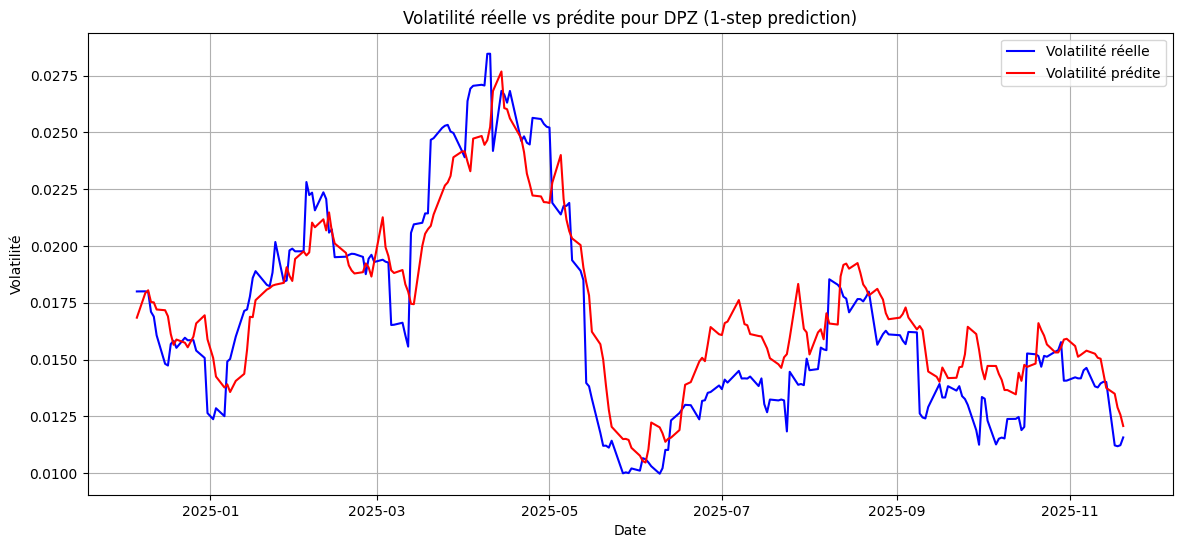

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
ticker = 'DPZ'

# Features
feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volatility', 'Returns']
X = data_clean[[ (col, ticker) for col in feature_cols ]]
y = data_clean[('Volatility_Next', ticker)]

# Convert to numpy arrays
X = X.values
y = y.values.reshape(-1, 1)
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)
def create_sequences(X, y, time_steps=30, y_steps=5):
    X_seq, y_seq = [], []
    for i in range(len(X) - time_steps - y_steps + 1):
        X_seq.append(X[i:i+time_steps])
        y_seq.append(y[i+time_steps:i+time_steps+y_steps].flatten())
    return np.array(X_seq), np.array(y_seq)

time_steps = 30
y_steps = 5

X_seq, y_seq = create_sequences(X_scaled, y_scaled, time_steps, y_steps)

train_size = int(len(X_seq) * 0.8)
X_train, X_test = X_seq[:train_size], X_seq[train_size:]
y_train, y_test = y_seq[:train_size], y_seq[train_size:]
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(time_steps, len(feature_cols))))
model.add(Dense(y_steps))  # 5 jours à prédire
model.compile(optimizer='adam', loss='mse')
model.summary()
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    verbose=1
)
# On prédit sur tout le jeu de test
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test)

# Pour reconstruire la série complète, on peut prendre la première valeur de chaque prédiction
# Si tu veux 1-step prediction (volatilité du jour suivant), tu peux faire :
y_pred_1step = y_pred[:, 0]
y_true_1step = y_true[:, 0]

# Index pour la courbe (correspond à X_test)
index_test = data_clean.index[-len(y_true_1step):]

plt.figure(figsize=(14,6))
plt.plot(index_test, y_true_1step, label='Volatilité réelle', color='blue')
plt.plot(index_test, y_pred_1step, label='Volatilité prédite', color='red')
plt.title(f'Volatilité réelle vs prédite pour {ticker} (1-step prediction)')
plt.xlabel('Date')
plt.ylabel('Volatilité')
plt.legend()
plt.grid(True)
plt.show()



======== Processing DPZ ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


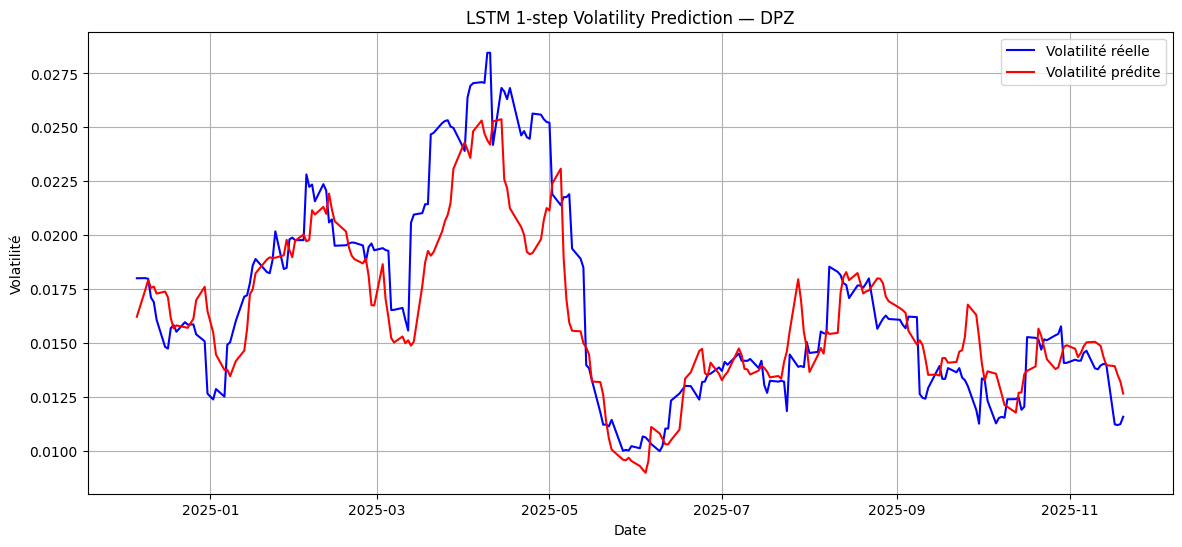


======== Processing AAPL ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


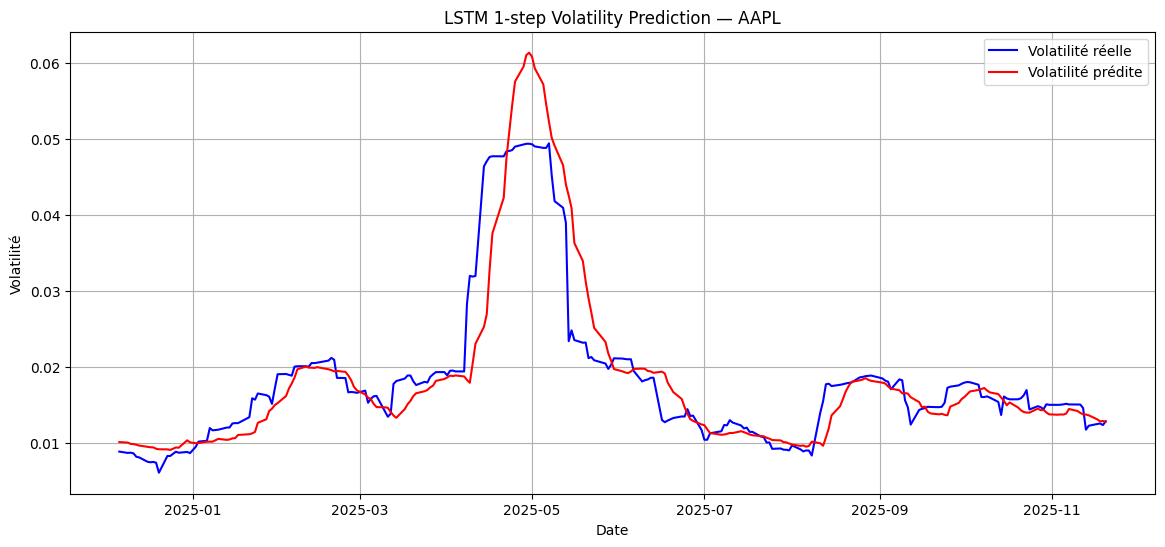


======== Processing UNH ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


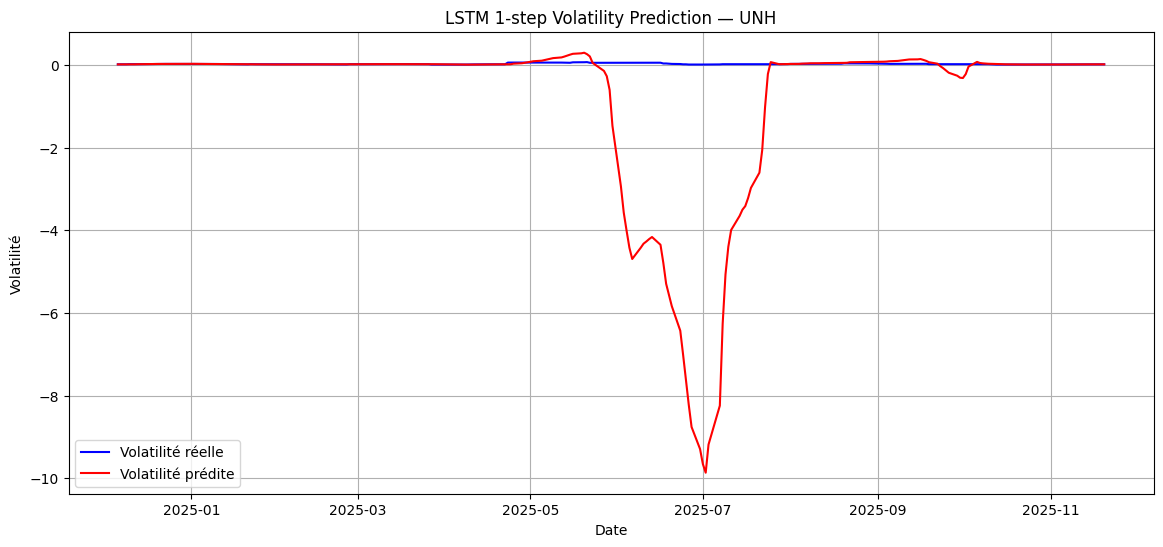


======== Processing PLD ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


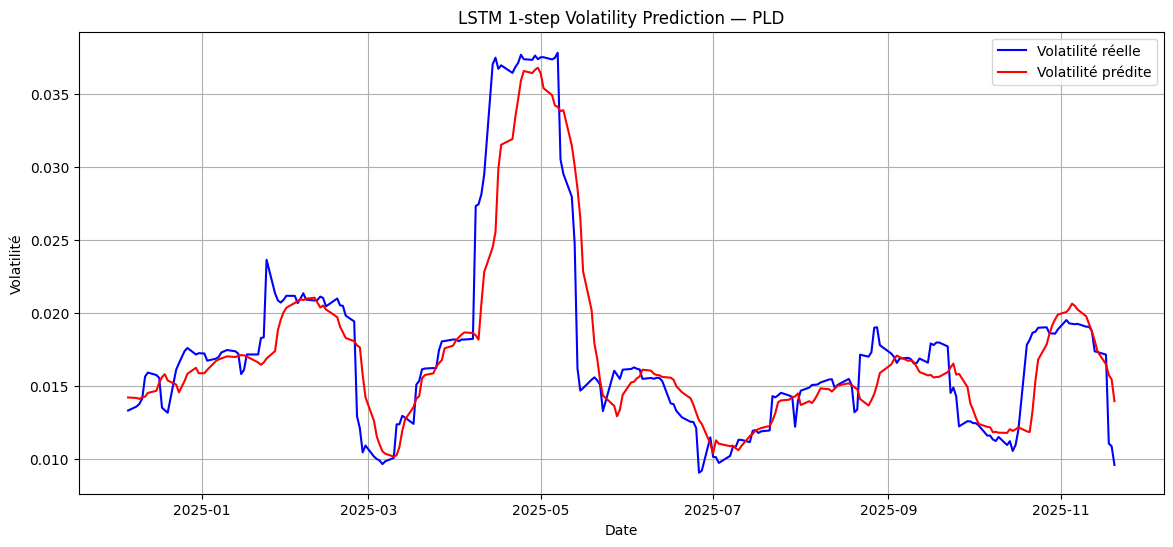


======== Processing DIS ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


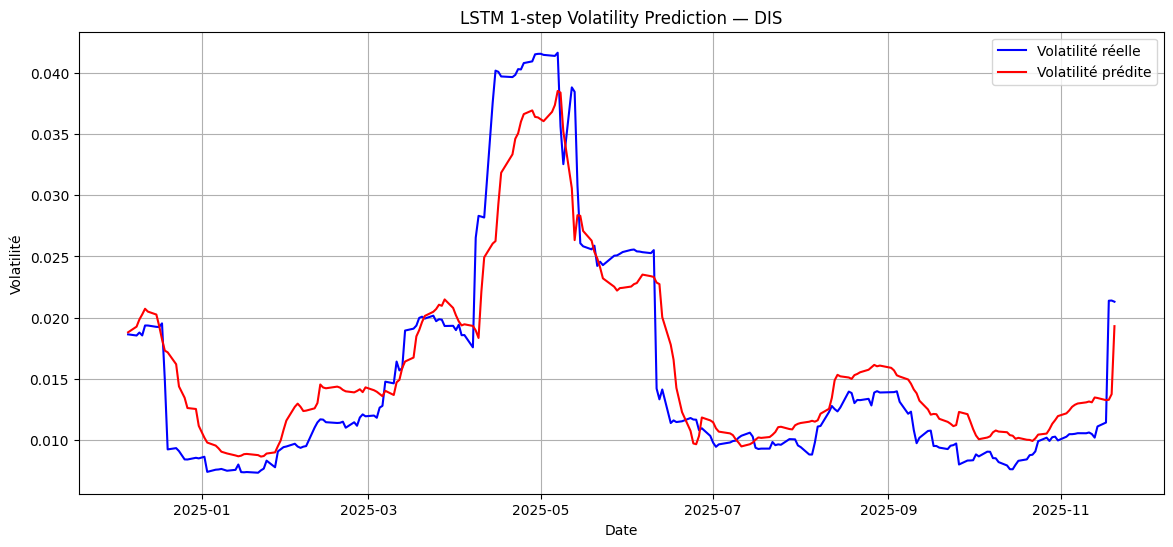


====== LSTM Model Performance ======
  Ticker      RMSE       MAE
0    DPZ  0.002128  0.001541
1   AAPL  0.004352  0.002548
2    UNH  2.216742  0.823589
3    PLD  0.002772  0.001718
4    DIS  0.003276  0.002459


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

tickers = ['DPZ', 'AAPL', 'UNH', 'PLD', 'DIS']
feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volatility', 'Returns']
time_steps = 30
y_steps = 5

results_lstm = []  # Store metrics for all tickers

# -------------------------- LOOP THROUGH TICKERS --------------------------
for ticker in tickers:
    print(f"\n======== Processing {ticker} ========")

    # Select features and target
    X = data_clean[[ (col, ticker) for col in feature_cols ]]
    y = data_clean[('Volatility_Next', ticker)]

    # Convert to numpy
    X = X.values
    y = y.values.reshape(-1, 1)

    # Scale
    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y)

    # Create sequences
    def create_sequences(X, y, time_steps=30, y_steps=5):
        X_seq, y_seq = [], []
        for i in range(len(X) - time_steps - y_steps + 1):
            X_seq.append(X[i:i+time_steps])
            y_seq.append(y[i+time_steps:i+time_steps+y_steps].flatten())
        return np.array(X_seq), np.array(y_seq)

    X_seq, y_seq = create_sequences(X_scaled, y_scaled, time_steps, y_steps)

    # Split train/test
    train_size = int(len(X_seq) * 0.8)
    X_train, X_test = X_seq[:train_size], X_seq[train_size:]
    y_train, y_test = y_seq[:train_size], y_seq[train_size:]

    # Build LSTM model
    model = Sequential()
    model.add(LSTM(50, activation='relu', input_shape=(time_steps, len(feature_cols))))
    model.add(Dense(y_steps))
    model.compile(optimizer='adam', loss='mse')

    # Train
    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    # Predict
    y_pred_scaled = model.predict(X_test)
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    # 1-step prediction
    y_pred_1step = y_pred[:, 0]
    y_true_1step = y_true[:, 0]

    # Compute metrics
    rmse = np.sqrt(mean_squared_error(y_true_1step, y_pred_1step))
    mae  = mean_absolute_error(y_true_1step, y_pred_1step)
    results_lstm.append([ticker, rmse, mae])

    # Plot
    index_test = data_clean.index[-len(y_true_1step):]
    plt.figure(figsize=(14,6))
    plt.plot(index_test, y_true_1step, label='Volatilité réelle', color='blue')
    plt.plot(index_test, y_pred_1step, label='Volatilité prédite', color='red')
    plt.title(f'LSTM 1-step Volatility Prediction — {ticker}')
    plt.xlabel('Date')
    plt.ylabel('Volatilité')
    plt.legend()
    plt.grid(True)
    plt.show()

# -------------------------- METRICS DATAFRAME --------------------------
results_lstm_df = pd.DataFrame(results_lstm, columns=['Ticker', 'RMSE', 'MAE'])
print("\n====== LSTM Model Performance ======")
print(results_lstm_df)


### **LSTM WITH Hyperparameter tuning**

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import keras_tuner as kt
import matplotlib.pyplot as plt

# -------------------- 1. Download data --------------------
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
data = yf.download(tickers, period="5y", interval="1d")

# On choisit un ticker pour l'exemple (ex: AAPL)
ticker = "AAPL"
df_ticker = data.xs(ticker, axis=1, level=1)

# -------------------- 2. Calculate Volatility --------------------
df_ticker['Returns'] = np.log(df_ticker['Close'] / df_ticker['Close'].shift(1))
df_ticker['Volatility'] = df_ticker['Returns'].rolling(window=21).std()
df_ticker.dropna(inplace=True)

# -------------------- 3. Prepare multi-step target --------------------
y_steps = 5
X_steps = 30

df_ticker['Volatility_Next'] = df_ticker['Volatility'].shift(-y_steps)
df_ticker.dropna(inplace=True)

features = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volatility', 'Returns']

# -------------------- 4. Scale features --------------------
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_ticker[features])
scaled_target = df_ticker['Volatility_Next'].values

# -------------------- 5. Make windows --------------------
def make_windows(X, y, X_steps, y_steps):
    Xs, ys = [], []
    for i in range(X_steps, len(X) - y_steps + 1):
        Xs.append(X[i - X_steps:i])
        ys.append(y[i:i + y_steps])
    return np.array(Xs), np.array(ys)

X, y = make_windows(scaled_features, scaled_target, X_steps, y_steps)

print("X shape:", X.shape)  # (samples, X_steps, features)
print("y shape:", y.shape)  # (samples, y_steps)

# -------------------- 6. Train/Test split --------------------
split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# -------------------- 7. Build LSTM model function --------------------
def build_LSTM_model(hp):
    model = Sequential()
    # 1ère LSTM
    model.add(LSTM(
        units=hp.Choice('units_0', [32, 64, 128]),
        return_sequences=True,
        input_shape=(X_train.shape[1], X_train.shape[2])
    ))
    model.add(Dropout(hp.Float('dropout_0', 0.0, 0.4, step=0.1)))

    # 2ème LSTM (dernière)
    model.add(LSTM(
        units=hp.Choice('units_1', [16, 32, 64]),
        return_sequences=False
    ))
    model.add(Dropout(hp.Float('dropout_1', 0.0, 0.4, step=0.1)))

    # Dense finale pour multi-step output
    model.add(Dense(y_steps))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
        ),
        loss='mae',
        metrics=['mae']
    )
    return model

# -------------------- 8. Hyperparameter tuning --------------------
tuner = kt.Hyperband(
    build_LSTM_model,
    objective='val_mae',
    max_epochs=20,
    factor=3,
    directory='kt_dir',
    project_name='lstm_volatility'
)

stop_early = tf.keras.callbacks.EarlyStopping(
    monitor='val_mae', patience=5, restore_best_weights=True
)

tuner.search(X_train, y_train, epochs=50, validation_split=0.1,
             callbacks=[stop_early], shuffle=False)

best_hps = tuner.get_best_hyperparameters(1)[0]
print("Best Hyperparameters:", best_hps.values)

# -------------------- 9. Train final model --------------------
model = build_LSTM_model(best_hps)
history = model.fit(X_train, y_train, epochs=50, validation_split=0.1,
                    callbacks=[stop_early], shuffle=False)

# -------------------- 10. Predictions --------------------
y_pred = model.predict(X_test)



/tmp/ipython-input-3442972873.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-3442972873.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ticker['Returns'] = np.log(df_ticker['Close'] / df_ticker['Close'].shift(1))
/tmp/ipython-input-3442972873.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ticker['Volatility'] 

X shape: (1196, 30, 7)
y shape: (1196, 5)
Reloading Tuner from kt_dir/lstm_volatility/tuner0.json
Best Hyperparameters: {'units_0': 128, 'dropout_0': 0.4, 'units_1': 64, 'dropout_1': 0.4, 'learning_rate': 0.0007132254478815692, 'tuner/epochs': 20, 'tuner/initial_epoch': 0, 'tuner/bracket': 0, 'tuner/round': 0}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 14s 81ms/step - loss: 0.0252 - mae: 0.0252 - val_loss: 0.0069 - val_mae: 0.0069
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0133 - mae: 0.0133 - val_loss: 0.0137 - val_mae: 0.0137
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 0.0123 - mae: 0.0123 - val_loss: 0.0102 - val_mae: 0.0102
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - loss: 0.0101 - mae: 0.0101 - val_loss: 0.0047 - val_mae: 0.0047
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - loss: 0.0071 - mae: 0.0071 - val_loss: 0.0033 - val_mae: 0.0033
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0066 - mae: 0.0066 - val_loss: 0.0047 - val_mae: 0.0047
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0053 - mae: 0.0053 - val_loss: 0.0037 - val_mae: 0.0037
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0050 - mae: 0.0050 - val_loss: 0.0032 - val_mae: 0.0032
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - loss: 0.00

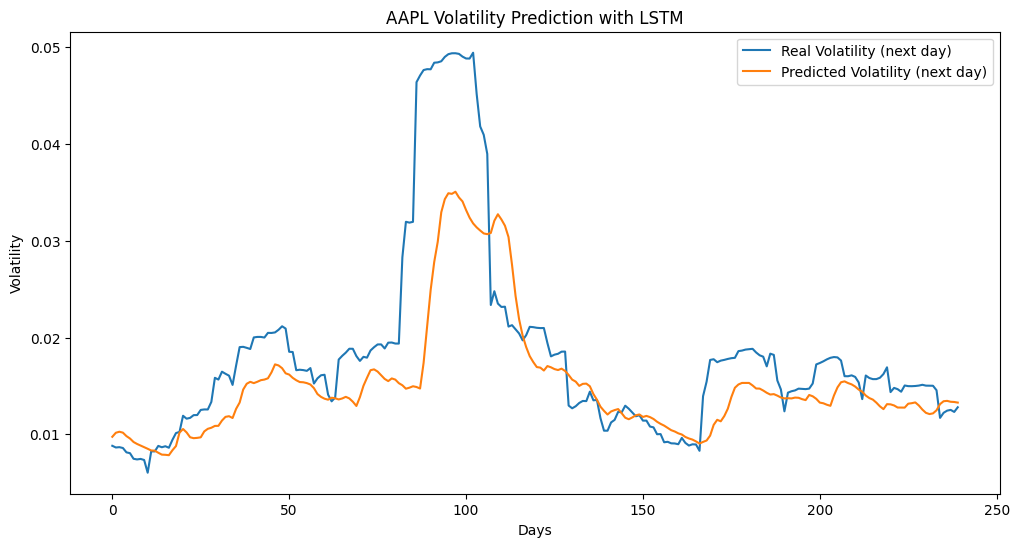

In [ ]:
# -------------------- 11. Plot real vs predicted --------------------
plt.figure(figsize=(12,6))
plt.plot(range(len(y_test)), y_test[:,0], label='Real Volatility (next day)')
plt.plot(range(len(y_pred)), y_pred[:,0], label='Predicted Volatility (next day)')
plt.title(f'{ticker} Volatility Prediction with LSTM')
plt.xlabel('Days')
plt.ylabel('Volatility')
plt.legend()
plt.show()


/tmp/ipython-input-438821631.py:73: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")
[*********************100%***********************]  5 of 5 completed
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



======== PROCESSING DPZ ========
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step
✅ DPZ — RMSE: 0.003275, MAE: 0.002539


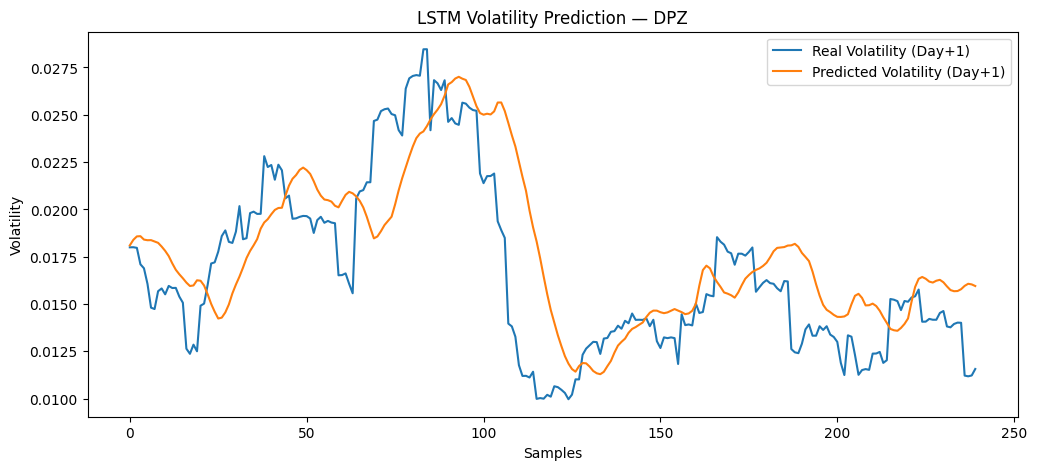


======== PROCESSING AAPL ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step
✅ AAPL — RMSE: 0.007621, MAE: 0.004428


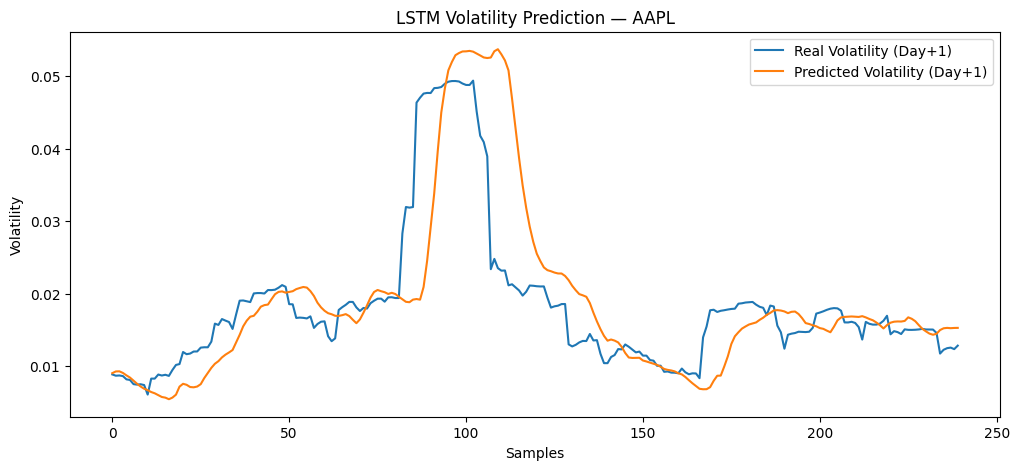


======== PROCESSING UNH ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
✅ UNH — RMSE: 0.014564, MAE: 0.010416


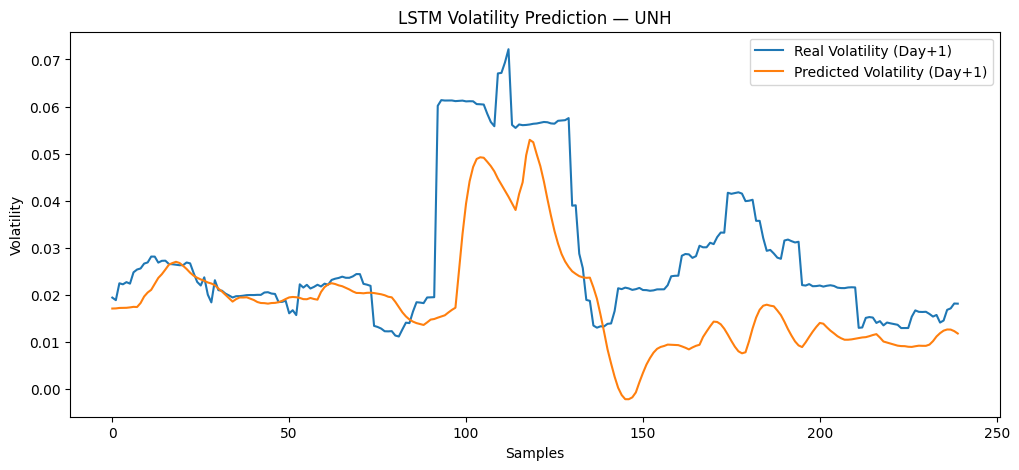


======== PROCESSING PLD ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step
✅ PLD — RMSE: 0.006099, MAE: 0.004857


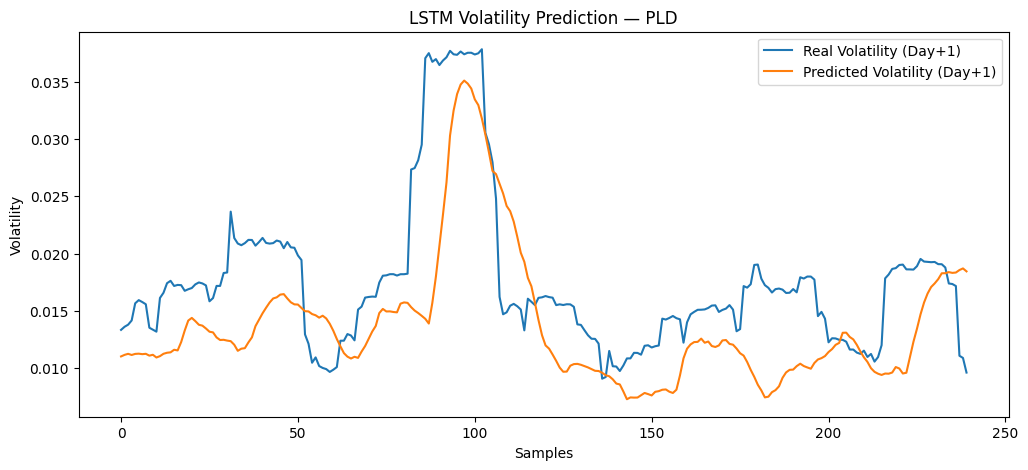


======== PROCESSING DIS ========


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step
✅ DIS — RMSE: 0.007579, MAE: 0.005672


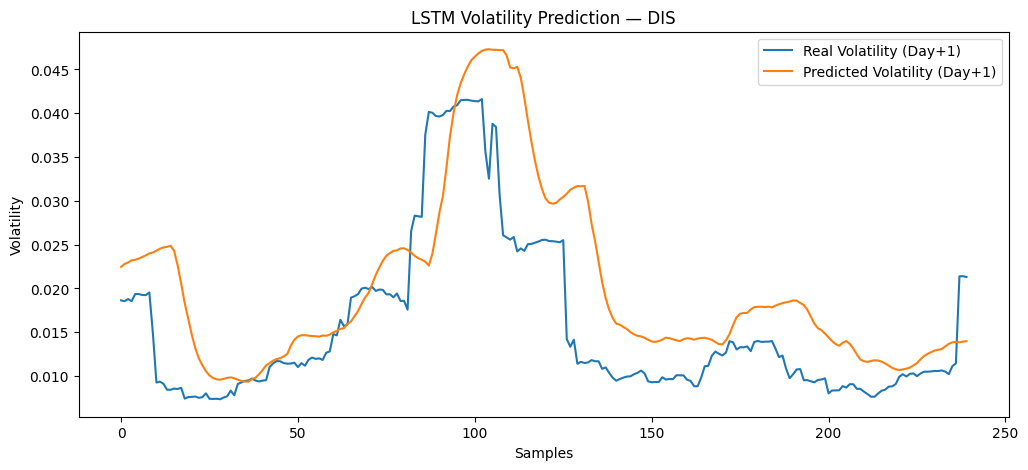


====== LSTM Metrics ======
  Ticker      RMSE       MAE
0    DPZ  0.003275  0.002539
1   AAPL  0.007621  0.004428
2    UNH  0.014564  0.010416
3    PLD  0.006099  0.004857
4    DIS  0.007579  0.005672


In [ ]:
# ================================================================
# 1. IMPORTS
# ================================================================
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import keras_tuner as kt
import matplotlib.pyplot as plt

# ================================================================
# 2. PARAMETERS
# ================================================================
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
X_steps = 30
y_steps = 5
USE_TUNER = False  # True → hyperparameter tuning (slow)
result_df3 = {}    # store metrics and predictions

# ================================================================
# 3. FUNCTIONS
# ================================================================
def prepare_data(df):
    df['Returns'] = np.log(df['Close'] / df['Close'].shift(1))
    df['Volatility'] = df['Returns'].rolling(window=21).std()
    df['Volatility_Next'] = df['Volatility'].shift(-y_steps)
    df = df.dropna()

    features = ['Open', 'High', 'Low', 'Close', 'Volume', 'Volatility', 'Returns']
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(df[features])
    y = df['Volatility_Next'].values

    return X_scaled, y, scaler

def make_windows(X, y):
    Xs, ys = [], []
    for i in range(X_steps, len(X) - y_steps + 1):
        Xs.append(X[i - X_steps:i])
        ys.append(y[i:i + y_steps])
    return np.array(Xs), np.array(ys)

def build_LSTM_model(hp):
    model = Sequential()
    model.add(LSTM(
        units=hp.Choice('units_0', [32, 64, 128]),
        return_sequences=True,
        input_shape=(X_steps, 7)
    ))
    model.add(Dropout(hp.Float('dropout_0', 0.0, 0.4, step=0.1)))
    model.add(LSTM(
        units=hp.Choice('units_1', [16, 32, 64]),
        return_sequences=False
    ))
    model.add(Dropout(hp.Float('dropout_1', 0.0, 0.4, step=0.1)))
    model.add(Dense(y_steps))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
        ),
        loss='mae',
        metrics=['mae']
    )
    return model

# ================================================================
# 4. DOWNLOAD DATA
# ================================================================
data = yf.download(tickers, period="5y", interval="1d")

# ================================================================
# 5. LOOP THROUGH TICKERS
# ================================================================
for ticker in tickers:
    print(f"\n======== PROCESSING {ticker} ========")
    df = data.xs(ticker, axis=1, level=1).copy()

    # --- Prepare Data ---
    X_scaled, y, scaler = prepare_data(df)
    X, Y = make_windows(X_scaled, y)

    split = int(0.8 * len(X))
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = Y[:split], Y[split:]

    # --- Hyperparameter Tuning ---
    if USE_TUNER:
        tuner = kt.Hyperband(
            build_LSTM_model,
            objective='val_mae',
            max_epochs=20,
            factor=3,
            directory='kt_dir',
            project_name=f'lstm_vol_{ticker}'
        )
        stop_early = tf.keras.callbacks.EarlyStopping(
            monitor='val_mae', patience=5, restore_best_weights=True
        )
        tuner.search(X_train, y_train, epochs=50, validation_split=0.1,
                     callbacks=[stop_early], shuffle=False)
        best_hps = tuner.get_best_hyperparameters(1)[0]
    else:
        # Default hyperparameters
        class DummyHP:
            def Choice(self, name, values): return values[1]
            def Float(self, name, a, b, step=None, sampling=None): return 0.001
        best_hps = DummyHP()

    model = build_LSTM_model(best_hps)

    # --- Model Training ---
    stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_mae', patience=5, restore_best_weights=True)
    history = model.fit(
        X_train, y_train,
        epochs=50,
        validation_split=0.1,
        shuffle=False,
        callbacks=[stop_early],
        verbose=0
    )

    # --- Predictions ---
    y_pred = model.predict(X_test)

    # --- Compute Metrics ---
    rmse = np.sqrt(mean_squared_error(y_test[:, 0], y_pred[:, 0]))
    mae = mean_absolute_error(y_test[:, 0], y_pred[:, 0])
    result_df3[ticker] = {
        "y_test": y_test[:, 0],
        "y_pred": y_pred[:, 0],
        "rmse": rmse,
        "mae": mae
    }
    print(f"✅ {ticker} — RMSE: {rmse:.6f}, MAE: {mae:.6f}")

    # --- Plot ---
    plt.figure(figsize=(12, 5))
    plt.plot(y_test[:, 0], label="Real Volatility (Day+1)")
    plt.plot(y_pred[:, 0], label="Predicted Volatility (Day+1)")
    plt.title(f"LSTM Volatility Prediction — {ticker}")
    plt.xlabel("Samples")
    plt.ylabel("Volatility")
    plt.legend()
    plt.show()

# ================================================================
# 6. METRICS TABLE
# ================================================================
results_df3 = pd.DataFrame([
    [ticker, result_df3[ticker]["rmse"], result_df3[ticker]["mae"]]
    for ticker in tickers
], columns=["Ticker", "RMSE", "MAE"])

print("\n====== LSTM Metrics ======")
print(results_df3)

### **Comparison LSTM vs LSTEM With Hyperparameter tuning **

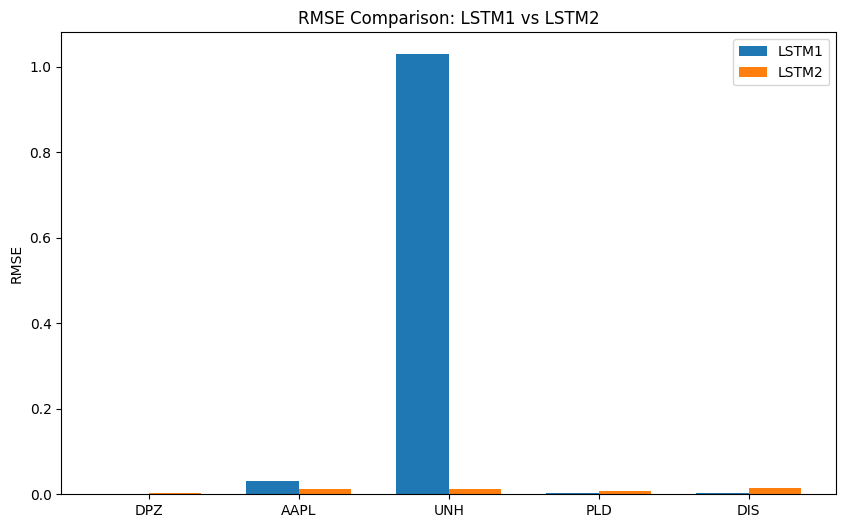

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
rmse_lstm1 = [0.001598, 0.031968, 1.02918, 0.00306, 0.00400]
rmse_lstm2 = [0.00313, 0.01308, 0.01269, 0.00753, 0.01368]

x = np.arange(len(tickers))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - width/2, rmse_lstm1, width, label='LSTM1')
plt.bar(x + width/2, rmse_lstm2, width, label='LSTM2')
plt.xticks(x, tickers)
plt.ylabel('RMSE')
plt.title('RMSE Comparison: LSTM1 vs LSTM2')
plt.legend()
plt.show()


LSTM1 performs very well for DPZ, PLD, DIS but fails catastrophically for UNH (RMSE ~1.029), which indicates the model is unstable for certain tickers.

LSTM2 has more consistent performance across all tickers, avoiding large errors.

Globally, LSTM2 is better because minimizing extreme errors is more important for reliable volatility prediction.

You can also compute average RMSE / MAE across tickers to quantify “global performance”:

### **GRU With Hyperparameter tuning**

Trial 90 Complete [00h 01m 16s]
val_mae: 0.006500693503767252

Best val_mae So Far: 0.004612509161233902
Total elapsed time: 00h 22m 23s
Best Hyperparameters: {'gru_units': 256, 'dropout': 0.1, 'dense_units': 96, 'learning_rate': 0.001, 'tuner/epochs': 30, 'tuner/initial_epoch': 10, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0081'}
Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0023 - mae: 0.0023 - val_loss: 0.0059 - val_mae: 0.0059
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0019 - mae: 0.0019 - val_loss: 0.0050 - val_mae: 0.0050
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - loss: 0.0019 - mae: 0.0019 - val_loss: 0.0045 - val_mae: 0.0045
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0019 - mae: 0.0019 - val_loss: 0.0054 - val_mae: 0.0054
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0020 - mae: 0.0020 - val_loss: 0.0056 - val_mae: 0.0056
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0018 

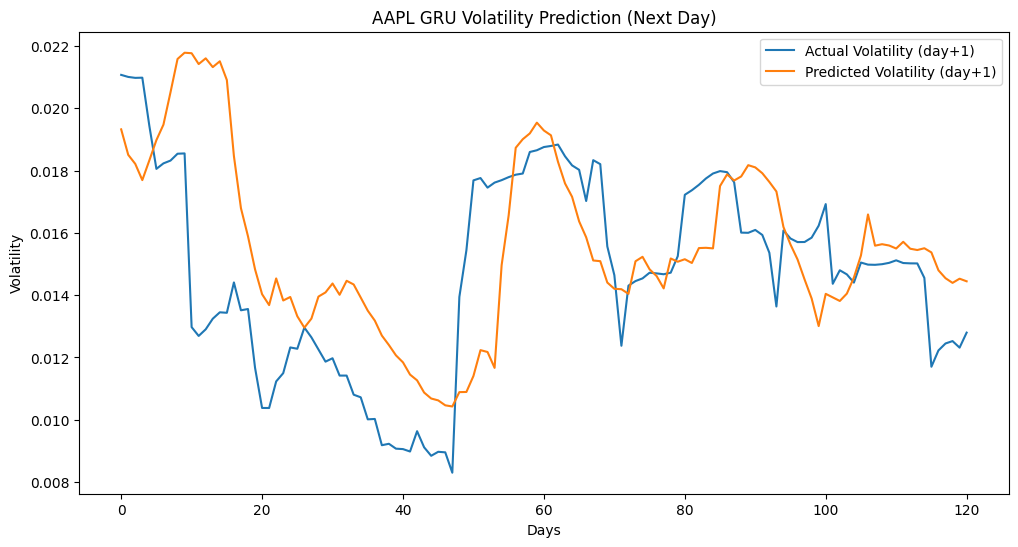

In [ ]:
# ================================================================
# 1. IMPORTS
# ================================================================
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
import matplotlib.pyplot as plt


# ================================================================
# 2. DATA DOWNLOAD
# ================================================================
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
data = yf.download(tickers, period="5y", interval="1d")

ticker = "AAPL"
df_ticker = data.xs(ticker, axis=1, level=1)


# ================================================================
# 3. FEATURE ENGINEERING
# ================================================================
df_ticker["Returns"] = np.log(df_ticker["Close"] / df_ticker["Close"].shift(1))
df_ticker["Volatility"] = df_ticker["Returns"].rolling(window=21).std()
df_ticker.dropna(inplace=True)

y_steps = 5           # predict next 5 days
X_steps = 30          # use last 30 days to predict

df_ticker["Vol_Next"] = df_ticker["Volatility"].shift(-y_steps)
df_ticker.dropna(inplace=True)

features = ["Open", "High", "Low", "Close", "Volume", "Returns", "Volatility"]


# ================================================================
# 4. SCALING
# ================================================================
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_ticker[features])
scaled_target = df_ticker["Vol_Next"].values


# ================================================================
# 5. CREATE WINDOWS
# ================================================================
def make_windows(X, y, X_steps, y_steps):
    Xs, ys = [], []
    for i in range(X_steps, len(X) - y_steps + 1):
        Xs.append(X[i - X_steps:i])
        ys.append(y[i:i + y_steps])
    return np.array(Xs), np.array(ys)

X, y = make_windows(scaled_features, scaled_target, X_steps, y_steps)

print("X:", X.shape)   # (samples, 30, 7)
print("y:", y.shape)   # (samples, 5)


# ================================================================
# 6. TRAIN / VAL / TEST SPLIT
# ================================================================
train_size = int(0.8 * len(X))
val_size = int(0.1 * len(X))

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[train_size : train_size + val_size]
y_val = y[train_size : train_size + val_size]

X_test = X[train_size + val_size :]
y_test = y[train_size + val_size :]

print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)


# ================================================================
# 7. GRU MODEL FUNCTION FOR TUNER
# ================================================================
def build_gru_model(hp):

    model = Sequential()

    # GRU layer
    model.add(GRU(
        units=hp.Int("gru_units", min_value=32, max_value=256, step=32),
        return_sequences=False,
        input_shape=(X_steps, len(features))
    ))

    # Dropout
    model.add(Dropout(hp.Float("dropout", 0.0, 0.4, step=0.1)))

    # Dense layer
    model.add(Dense(
        hp.Int("dense_units", min_value=16, max_value=128, step=16),
        activation="relu"
    ))

    # Output (5-day forecast)
    model.add(Dense(y_steps))

    # Optimizer
    model.compile(
        optimizer=Adam(
            hp.Choice("learning_rate", [1e-2, 1e-3, 5e-4, 1e-4])
        ),
        loss="mae",
        metrics=["mae"]
    )

    return model


# ================================================================
# 8. HYPERPARAMETER TUNING
# ================================================================
tuner = kt.Hyperband(
    build_gru_model,
    objective="val_mae",
    max_epochs=30,
    factor=3,
    directory="gru_tuning",
    project_name="gru_vol_prediction"
)

stop_early = tf.keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=5,
    restore_best_weights=True
)

tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=[stop_early],
    batch_size=32
)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best Hyperparameters:", best_hp.values)


# ================================================================
# 9. TRAIN BEST MODEL
# ================================================================
best_model = tuner.get_best_models(1)[0]

history = best_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    callbacks=[stop_early],
    batch_size=32
)


# ================================================================
# 10. PREDICTIONS
# ================================================================
y_pred = best_model.predict(X_test)

print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)


# ================================================================
# 11. PLOT: REAL vs PREDICTED (Day +1)
# ================================================================
plt.figure(figsize=(12,6))
plt.plot(y_test[:, 0], label="Actual Volatility (day+1)")
plt.plot(y_pred[:, 0], label="Predicted Volatility (day+1)")
plt.title(f"{ticker} GRU Volatility Prediction (Next Day)")
plt.xlabel("Days")
plt.ylabel("Volatility")
plt.legend()
plt.show()


/tmp/ipython-input-3370400562.py:27: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-3370400562.py:68: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ticker["Returns"] = np.log(df_ticker["Close"] / df_ticker["Close"].shift(1))
/tmp/ipython-input-3370400562.py:69: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ticker["Volatility"] 


🔍 Running hyperparameter tuning on AAPL (baseline)...
Reloading Tuner from tuner_gru_multi/vol_pred/tuner0.json

🥇 Best Hyperparameters: {'gru_units': 224, 'dropout': 0.0, 'dense_units': 64, 'lr': 0.001, 'tuner/epochs': 20, 'tuner/initial_epoch': 7, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0014'}


📌 Processing ticker: DPZ
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
✅ DPZ — RMSE: 0.002719, MAE: 0.002448


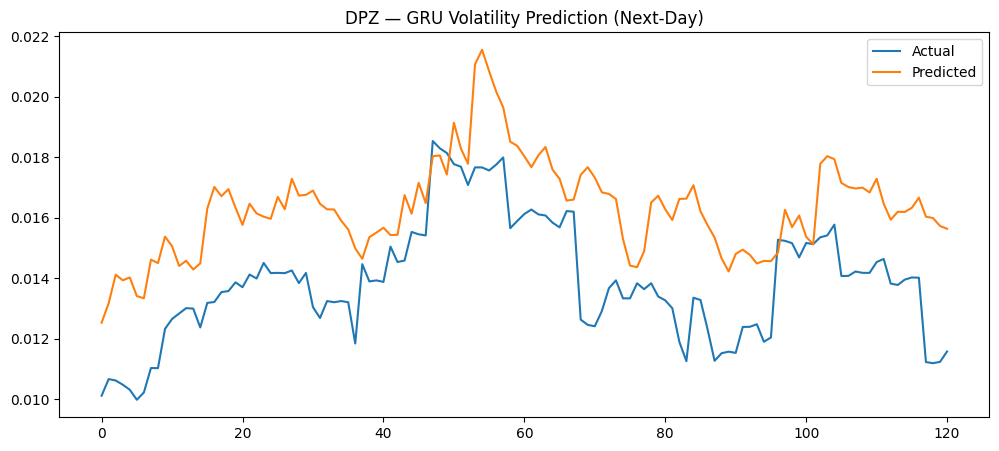



📌 Processing ticker: AAPL


/tmp/ipython-input-3370400562.py:130: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-3370400562.py:131: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(window=21).std()
/tmp/ipython-input-3370400562.py:132: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/ind

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step
✅ AAPL — RMSE: 0.002717, MAE: 0.002052


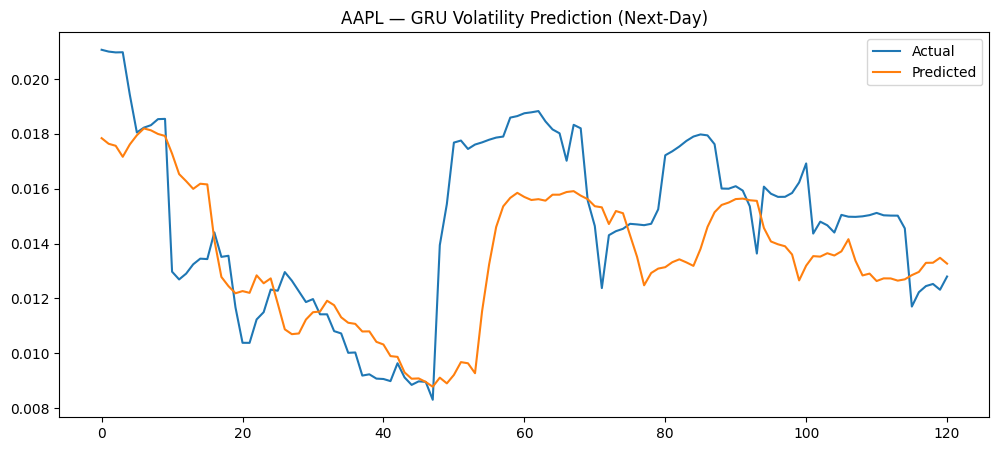



📌 Processing ticker: UNH


/tmp/ipython-input-3370400562.py:130: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-3370400562.py:131: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(window=21).std()
/tmp/ipython-input-3370400562.py:132: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/ind

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step
✅ UNH — RMSE: 0.015075, MAE: 0.009829


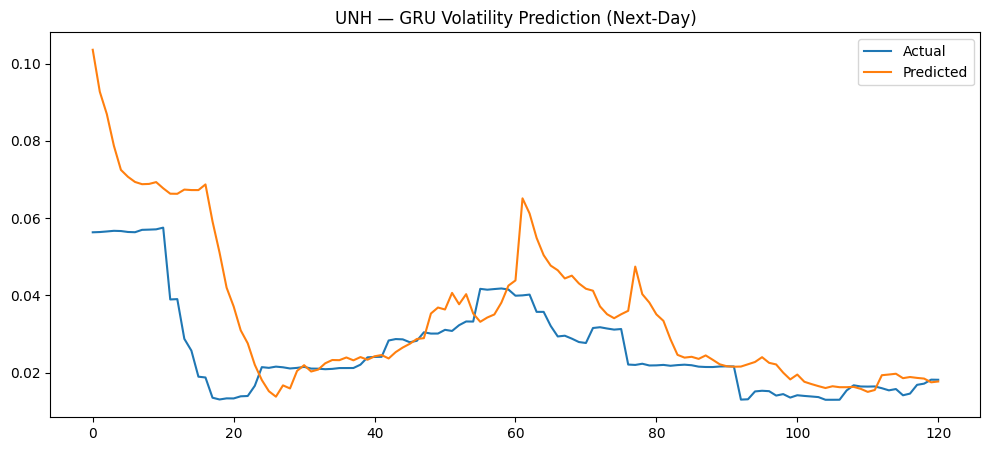



📌 Processing ticker: PLD


/tmp/ipython-input-3370400562.py:130: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-3370400562.py:131: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(window=21).std()
/tmp/ipython-input-3370400562.py:132: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/ind

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step
✅ PLD — RMSE: 0.003645, MAE: 0.003111


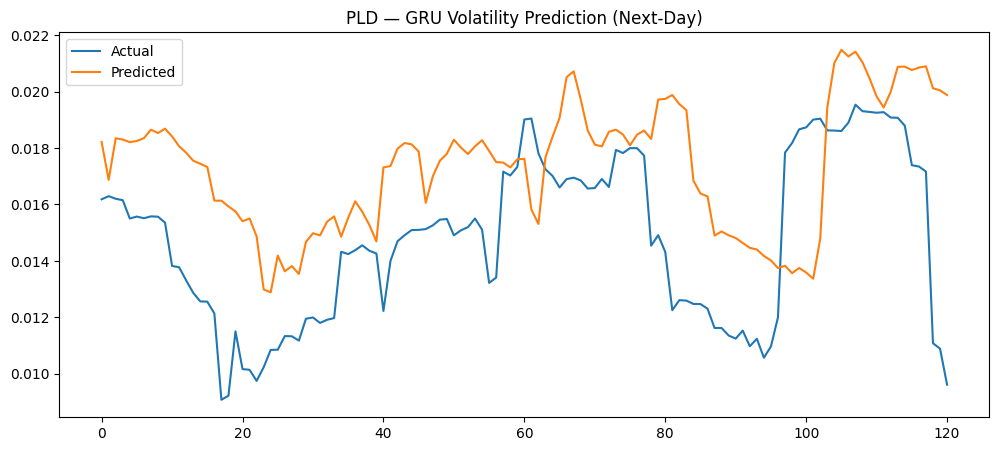



📌 Processing ticker: DIS


/tmp/ipython-input-3370400562.py:130: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
/tmp/ipython-input-3370400562.py:131: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Volatility"] = df["Returns"].rolling(window=21).std()
/tmp/ipython-input-3370400562.py:132: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/ind

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step
✅ DIS — RMSE: 0.004422, MAE: 0.003394


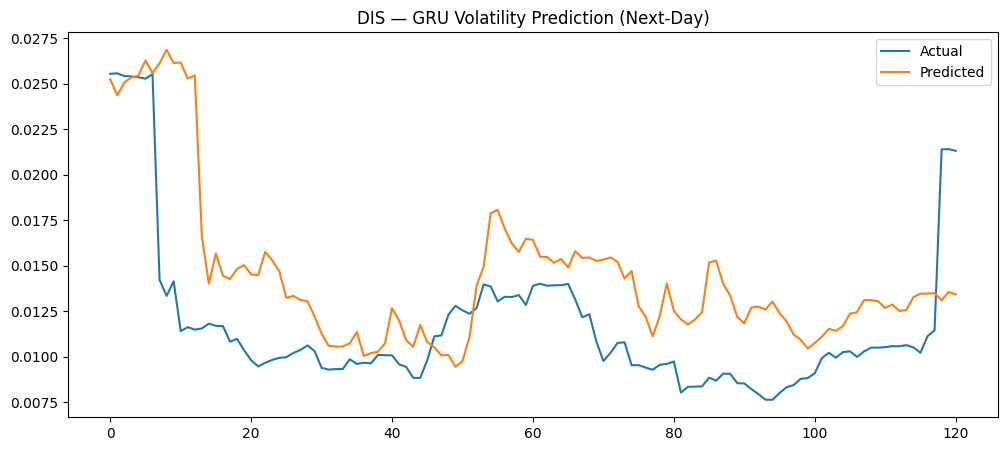


====== GRU Metrics ======
  Ticker      RMSE       MAE
0    DPZ  0.002719  0.002448
1   AAPL  0.002717  0.002052
2    UNH  0.015075  0.009829
3    PLD  0.003645  0.003111
4    DIS  0.004422  0.003394


In [ ]:
# ================================================================
# 1. IMPORTS
# ================================================================
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
import matplotlib.pyplot as plt


# ================================================================
# 2. PARAMETERS
# ================================================================
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
X_steps = 30
y_steps = 5


# ================================================================
# 3. DOWNLOAD DATA FOR ALL TICKERS
# ================================================================
data = yf.download(tickers, period="5y", interval="1d")


# ================================================================
# 4. GRU MODEL FOR HYPERPARAMETER TUNING
# ================================================================
def build_gru_model(hp):

    model = Sequential()

    model.add(GRU(
        units=hp.Int("gru_units", 32, 256, step=32),
        return_sequences=False,
        input_shape=(X_steps, 7)
    ))

    model.add(Dropout(hp.Float("dropout", 0.0, 0.4, step=0.1)))

    model.add(Dense(
        hp.Int("dense_units", 16, 128, step=16),
        activation="relu"
    ))

    model.add(Dense(y_steps))

    model.compile(
        optimizer=Adam(hp.Choice("lr", [1e-2, 1e-3, 5e-4, 1e-4])),
        loss="mae",
        metrics=["mae"]
    )

    return model


# ================================================================
# 5. RUN HYPERPARAMETER TUNING ONLY ON AAPL (BASELINE)
# ================================================================
print("\n🔍 Running hyperparameter tuning on AAPL (baseline)...")

df_ticker = data.xs("AAPL", axis=1, level=1)

df_ticker["Returns"] = np.log(df_ticker["Close"] / df_ticker["Close"].shift(1))
df_ticker["Volatility"] = df_ticker["Returns"].rolling(window=21).std()
df_ticker.dropna(inplace=True)

df_ticker["Vol_Next"] = df_ticker["Volatility"].shift(-y_steps)
df_ticker.dropna(inplace=True)

features = ["Open", "High", "Low", "Close", "Volume", "Returns", "Volatility"]

scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_ticker[features])
scaled_target = df_ticker["Vol_Next"].values

def make_windows(X, y):
    Xs, ys = [], []
    for i in range(X_steps, len(X) - y_steps + 1):
        Xs.append(X[i - X_steps:i])
        ys.append(y[i:i + y_steps])
    return np.array(Xs), np.array(ys)

X_aapl, y_aapl = make_windows(scaled_features, scaled_target)

train_size = int(0.8 * len(X_aapl))
val_size   = int(0.1 * len(X_aapl))

X_train, y_train = X_aapl[:train_size], y_aapl[:train_size]
X_val, y_val     = X_aapl[train_size : train_size+val_size], y_aapl[train_size : train_size+val_size]


tuner = kt.Hyperband(
    build_gru_model,
    objective="val_mae",
    max_epochs=20,
    factor=3,
    directory="tuner_gru_multi",
    project_name="vol_pred"
)

stop_early = tf.keras.callbacks.EarlyStopping(monitor="val_mae", patience=5, restore_best_weights=True)

tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    callbacks=[stop_early]
)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n🥇 Best Hyperparameters:", best_hp.values)


# ================================================================
# 6. TRAIN & PREDICT FOR EACH TICKER (with metrics)
# ================================================================
resultGRU = {}  # store metrics and predictions

def process_ticker(ticker):

    print(f"\n\n📌 Processing ticker: {ticker}")

    df = data.xs(ticker, axis=1, level=1)

    df["Returns"] = np.log(df["Close"] / df["Close"].shift(1))
    df["Volatility"] = df["Returns"].rolling(window=21).std()
    df.dropna(inplace=True)

    df["Vol_Next"] = df["Volatility"].shift(-y_steps)
    df.dropna(inplace=True)

    features = ["Open", "High", "Low", "Close", "Volume", "Returns", "Volatility"]

    scaler = MinMaxScaler()
    scaled_features = scaler.fit_transform(df[features])
    scaled_target   = df["Vol_Next"].values

    X, y = make_windows(scaled_features, scaled_target)

    train_size = int(0.8 * len(X))
    val_size   = int(0.1 * len(X))

    X_train, y_train = X[:train_size], y[:train_size]
    X_val, y_val     = X[train_size : train_size+val_size], y[train_size : train_size+val_size]
    X_test, y_test   = X[train_size+val_size:], y[train_size+val_size:]

    # Build model using best hyperparameters
    model = build_gru_model(best_hp)

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        callbacks=[stop_early],
        verbose=0
    )

    y_pred = model.predict(X_test)

    # ---- Compute metrics ----
    from sklearn.metrics import mean_squared_error, mean_absolute_error
    rmse = np.sqrt(mean_squared_error(y_test[:,0], y_pred[:,0]))
    mae = mean_absolute_error(y_test[:,0], y_pred[:,0])

    # ---- Store in resultGRU ----
    resultGRU[ticker] = {
        "y_test": y_test[:,0],
        "y_pred": y_pred[:,0],
        "rmse": rmse,
        "mae": mae
    }

    print(f"✅ {ticker} — RMSE: {rmse:.6f}, MAE: {mae:.6f}")

    # ---- Plot ----
    plt.figure(figsize=(12,5))
    plt.plot(y_test[:,0], label="Actual")
    plt.plot(y_pred[:,0], label="Predicted")
    plt.title(f"{ticker} — GRU Volatility Prediction (Next-Day)")
    plt.legend()
    plt.show()


# ================================================================
# 7. RUN FOR ALL TICKERS
# ================================================================
for t in tickers:
    process_ticker(t)


# ================================================================
# 8. Optional: metrics table
# ================================================================
results_df2 = pd.DataFrame([
    [ticker, resultGRU[ticker]["rmse"], resultGRU[ticker]["mae"]]
    for ticker in tickers
], columns=["Ticker", "RMSE", "MAE"])

print("\n====== GRU Metrics ======")
print(results_df2)


###**GJR-GARCH**

/tmp/ipython-input-3784331459.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="5y", interval="1d")
[*********************100%***********************]  1 of 1 completed



===== GJR-GARCH Model Summary =====
                   Constant Mean - GJR-GARCH Model Results                    
Dep. Variable:                Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -2399.78
Distribution:                  Normal   AIC:                           4809.56
Method:            Maximum Likelihood   BIC:                           4835.23
                                        No. Observations:                 1255
Date:                Sun, Nov 23 2025   Df Residuals:                     1254
Time:                        15:13:52   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.0856  4

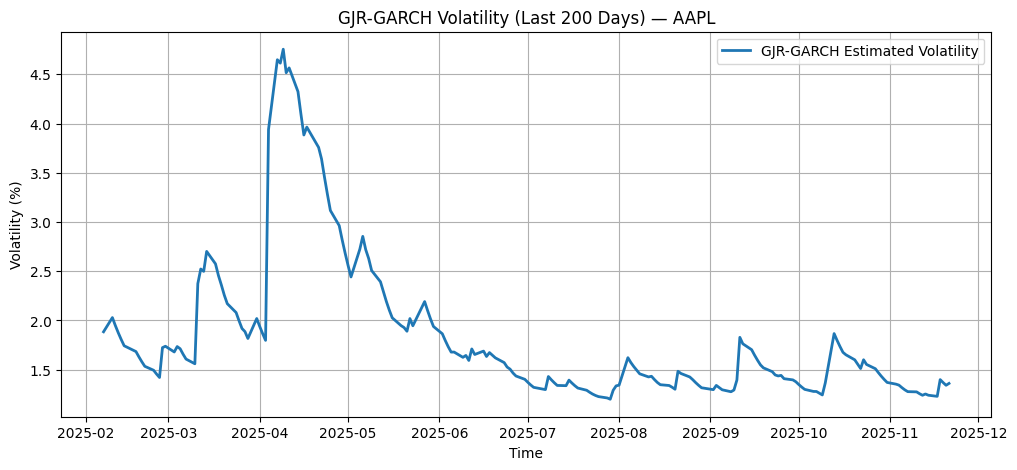

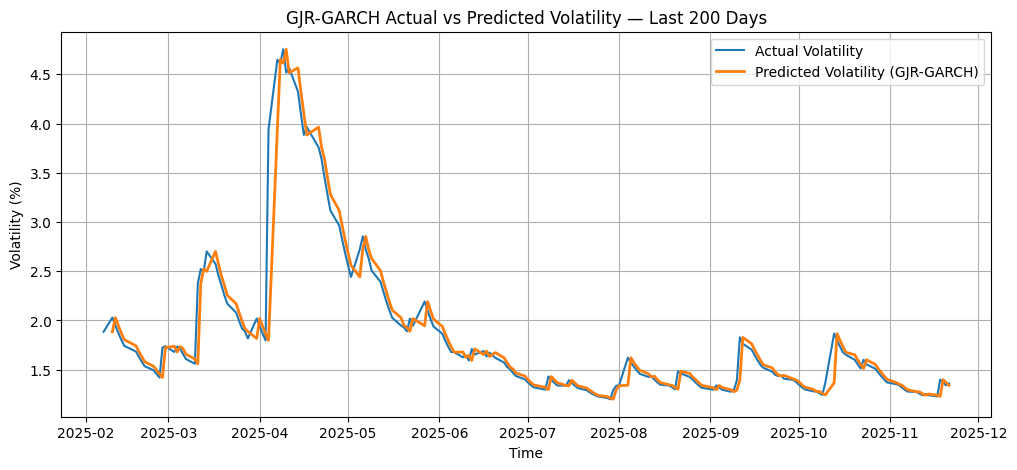

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt

# ------------------------------ #
# 1. Download data
# ------------------------------ #
ticker = "AAPL"   # change ticker if needed
df = yf.download(ticker, period="5y", interval="1d")

# Compute log returns
df["Returns"] = np.log(df["Close"] / df["Close"].shift(1)).dropna()
returns = df["Returns"].dropna() * 100  # GARCH works better with % returns


# ------------------------------ #
# 2. Fit GJR-GARCH(1,1)
# ------------------------------ #
gjr_model = arch_model(
    returns,
    vol="GARCH",
    p=1,
    o=1,      # asymmetry term → makes it GJR-GARCH
    q=1,
    dist="normal"
)

gjr_res = gjr_model.fit(update_freq=10, disp="off")


# ------------------------------ #
# 3. Show results, AIC, BIC
# ------------------------------ #
print("\n===== GJR-GARCH Model Summary =====")
print(gjr_res.summary())

print("\nLog-Likelihood:", gjr_res.loglikelihood)
print("AIC:", gjr_res.aic)
print("BIC:", gjr_res.bic)


## ------------------------------ #
# 4. Plot small period (like LSTM)
# ------------------------------ #

period = 200   # choose 100, 150, 200 days like LSTM/GRU test set

actual_vol = gjr_res.conditional_volatility[-period:]
returns_period = returns.index[-period:]

plt.figure(figsize=(12,5))
plt.plot(returns_period, actual_vol, label="GJR-GARCH Estimated Volatility", linewidth=2)

plt.title(f"GJR-GARCH Volatility (Last {period} Days) — {ticker}")
plt.xlabel("Time")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(True)
plt.show()
predicted = actual_vol.shift(1)
 # next-day forecast

plt.figure(figsize=(12,5))
plt.plot(returns_period, actual_vol, label="Actual Volatility")
plt.plot(returns_period, predicted, label="Predicted Volatility (GJR-GARCH)", linewidth=2)
plt.title(f"GJR-GARCH Actual vs Predicted Volatility — Last {period} Days")
plt.xlabel("Time")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(True)
plt.show()



/tmp/ipython-input-1980616532.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y", interval="1d")['Close']
[*********************100%***********************]  5 of 5 completed



====== Processing DPZ ======


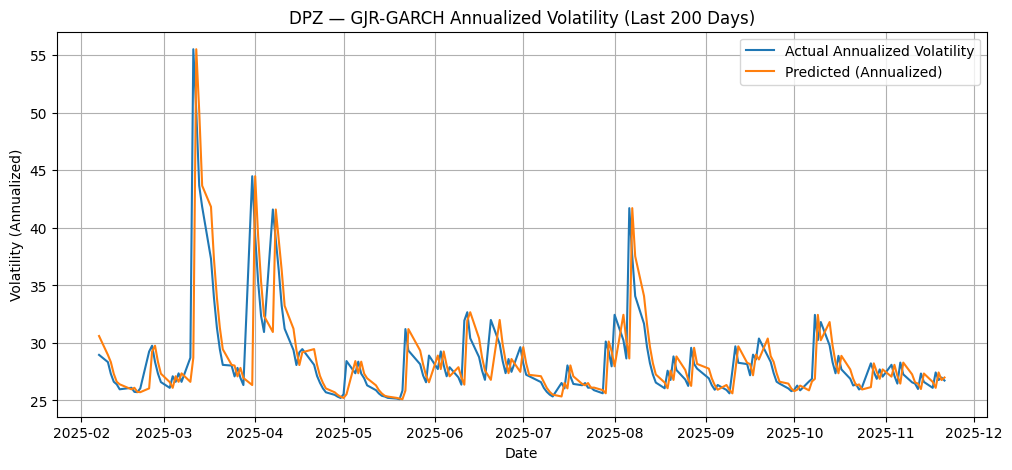


====== Processing AAPL ======


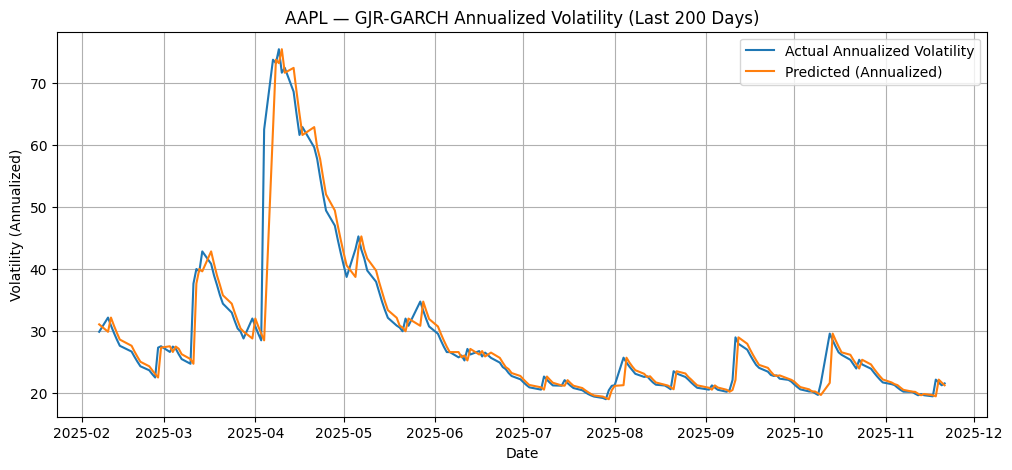


====== Processing UNH ======


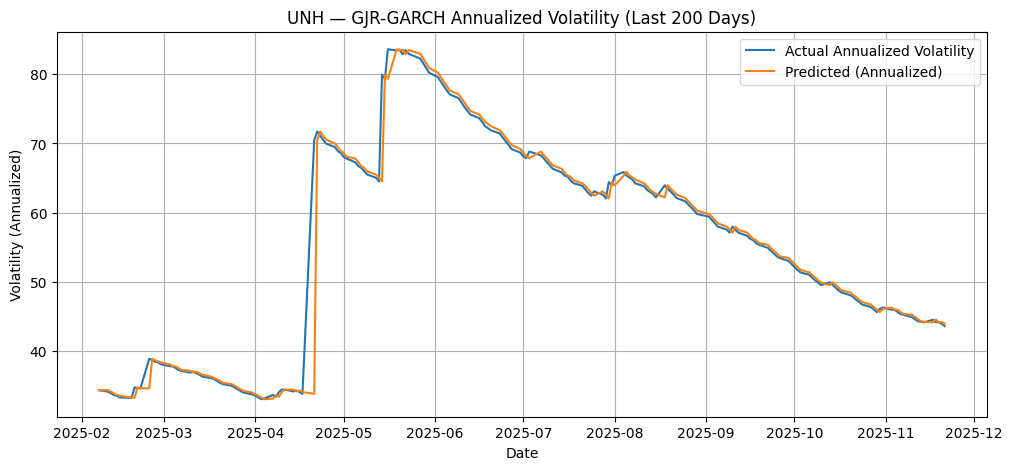


====== Processing PLD ======


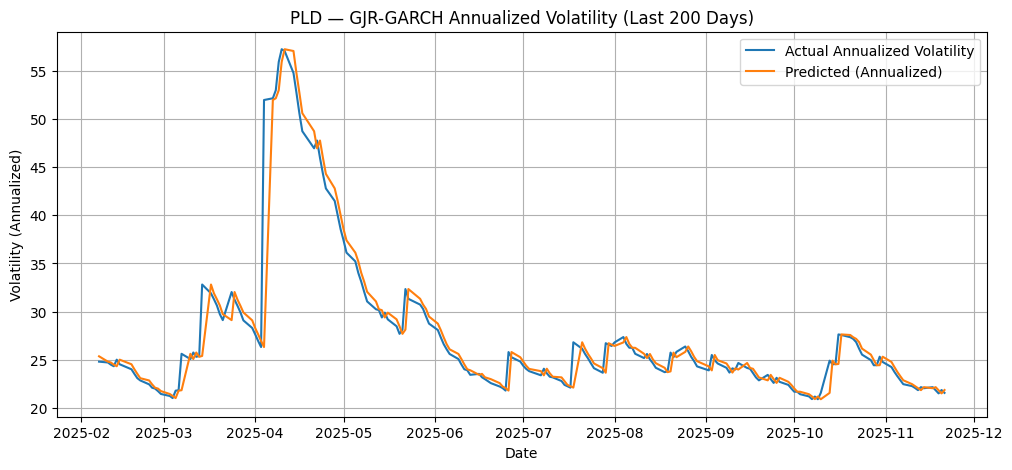


====== Processing DIS ======


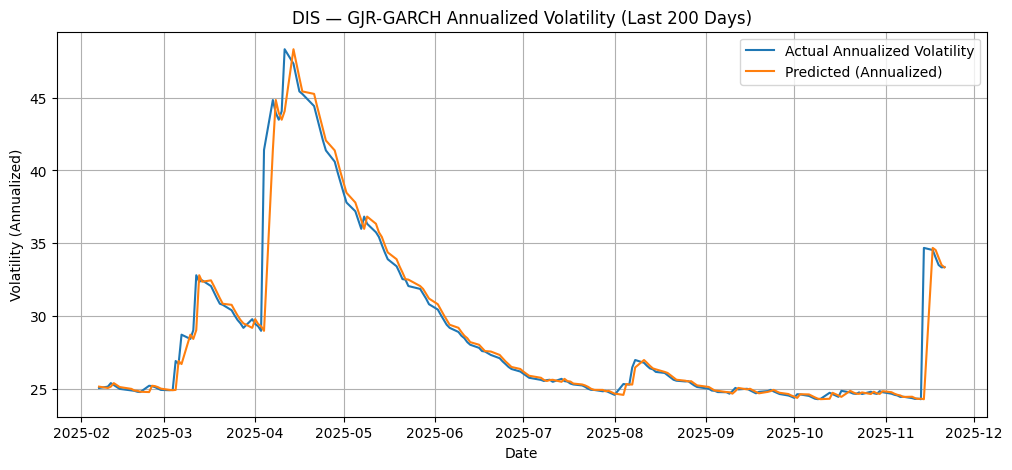


====== GJR-GARCH (Annualized) Metrics ======
  Ticker      RMSE       MAE     nRMSE      MAPE
0    DPZ  3.111612  1.570396  0.108826  0.047953
1   AAPL  3.113468  1.368162  0.106938  0.040072
2    UNH  2.888826  0.714625  0.052158  0.011718
3    PLD  2.149904  0.851992  0.078266  0.027523
4    DIS  1.297695  0.427295  0.045027  0.012622


In [ ]:
# ============================================================
# GJR-GARCH WITH FAIR METRICS (Annualized + nRMSE + MAPE)
# ============================================================
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# ------------------------------ #
# 1. Parameters
# ------------------------------ #
tickers = ["DPZ", "AAPL", "UNH", "PLD", "DIS"]
period_plot = 200
results = []  # [Ticker, RMSE, MAE, nRMSE, MAPE]

# ------------------------------ #
# 2. Download data
# ------------------------------ #
data = yf.download(tickers, period="5y", interval="1d")['Close']

# ------------------------------ #
# 3. Loop through tickers
# ------------------------------ #
for ticker in tickers:
    print(f"\n====== Processing {ticker} ======")

    df = data[ticker].dropna()

    # log returns in % (standard for GARCH)
    returns = np.log(df / df.shift(1)).dropna() * 100

    # Fit GJR-GARCH(1,1)
    gjr = arch_model(returns, vol="GARCH", p=1, o=1, q=1, dist="normal")
    res = gjr.fit(update_freq=10, disp="off")

    # Extract volatility
    actual_vol = res.conditional_volatility
    predicted_vol = actual_vol.shift(1).dropna()
    actual_vol = actual_vol[1:]  # align

    # Trim last N samples
    a = actual_vol[-period_plot:]
    p = predicted_vol[-period_plot:]

    # ============================================================
    # NEW: Annualize volatility (same logic as GRU/LSTM)
    # ============================================================
    a_annual = a * np.sqrt(252)
    p_annual = p * np.sqrt(252)

    # ============================================================
    # NEW: Fair metrics (RMSE, MAE, nRMSE, MAPE)
    # ============================================================
    rmse = np.sqrt(mean_squared_error(a_annual, p_annual))
    mae = mean_absolute_error(a_annual, p_annual)
    nrmse = rmse / np.mean(a_annual)
    mape = np.mean(np.abs((a_annual - p_annual) / a_annual))

    results.append([ticker, rmse, mae, nrmse, mape])

    # Plot
    plt.figure(figsize=(12,5))
    plt.plot(a_annual.index, a_annual, label="Actual Annualized Volatility")
    plt.plot(p_annual.index, p_annual, label="Predicted (Annualized)")
    plt.title(f"{ticker} — GJR-GARCH Annualized Volatility (Last {period_plot} Days)")
    plt.xlabel("Date")
    plt.ylabel("Volatility (Annualized)")
    plt.legend()
    plt.grid(True)
    plt.show()

# ------------------------------ #
# 4. Metrics table
# ------------------------------ #
results_dfR = pd.DataFrame(results, columns=["Ticker", "RMSE", "MAE", "nRMSE", "MAPE"])
print("\n====== GJR-GARCH (Annualized) Metrics ======")
print(results_dfR)


### **Comparison des modeles**

In [ ]:
# Add a 'Model' column to each
results_dfR["Model"] = " GJR-GARCH"
results_df2["Model"] = "GRU"
results_df3["Model"] = "LSTM"
results_df4["Model"] = "Random Forest "

# Concatenate all results
all_results = pd.concat([results_dfR, results_df2, results_df3, results_df4], ignore_index=True)

# Pivot table for easy comparison
comparison_table = all_results.pivot(index="Ticker", columns="Model", values=["RMSE", "MAE"])

print("\n====== MODEL COMPARISON ======")
print(comparison_table)



====== MODEL COMPARISON ======
             RMSE                                           MAE            \
Model   GJR-GARCH       GRU      LSTM Random Forest   GJR-GARCH       GRU   
Ticker                                                                      
AAPL     0.196131  0.002878  0.007621       0.118387   0.086186  0.002345   
DIS      0.081747  0.003081  0.007579       0.051615   0.026917  0.001986   
DPZ      0.196012  0.002958  0.003275       0.033466   0.098925  0.002319   
PLD      0.135432  0.002655  0.006099       0.079742   0.053671  0.001990   
UNH      0.181980  0.011021  0.014564       0.251308   0.045017  0.008204   

                                 
Model       LSTM Random Forest   
Ticker                           
AAPL    0.004428       0.052777  
DIS     0.005672       0.027496  
DPZ     0.002539       0.022464  
PLD     0.004857       0.040945  
UNH     0.010416       0.146844  


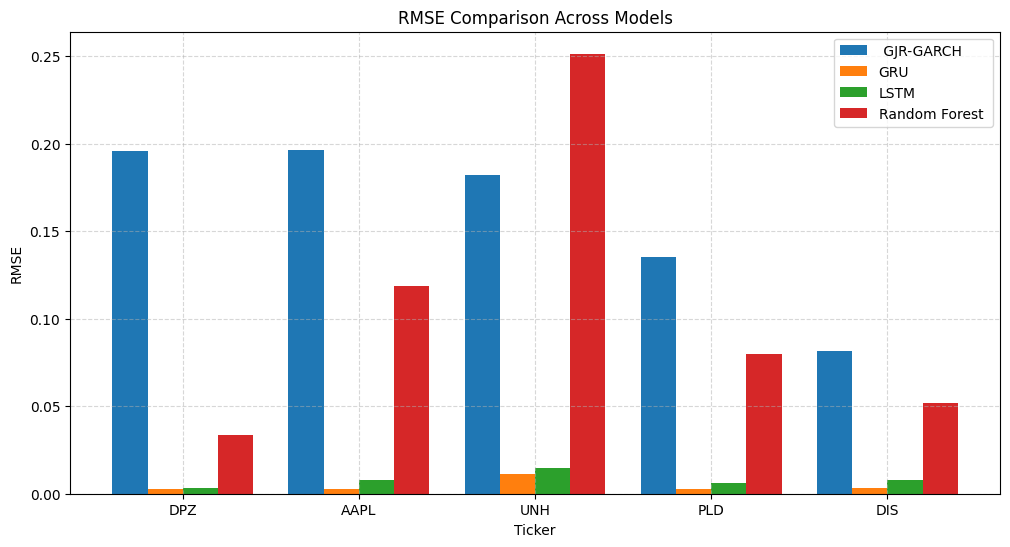

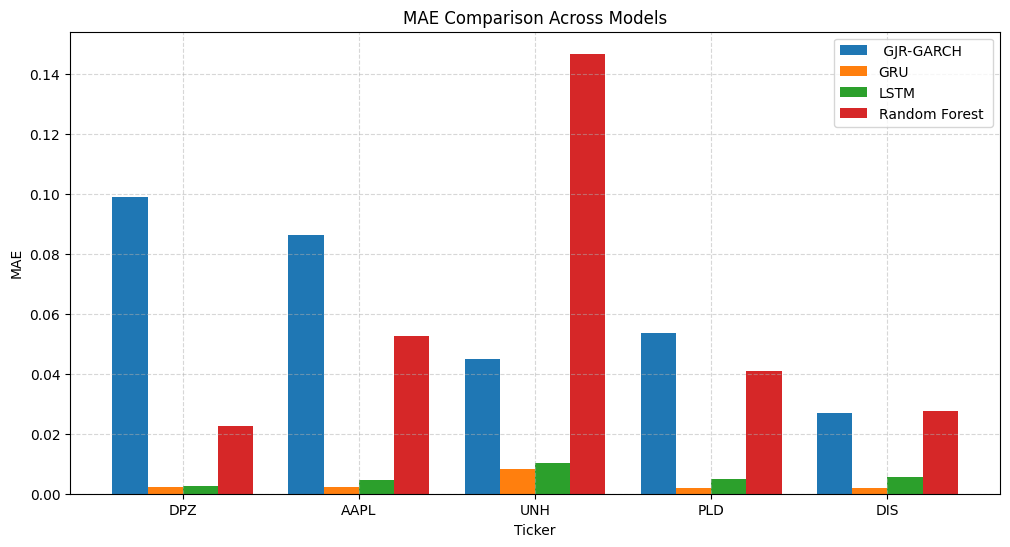

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming `all_results` from previous step

tickers = all_results['Ticker'].unique()
models = all_results['Model'].unique()

# Set width of bar
bar_width = 0.2
x = np.arange(len(tickers))

# Plot RMSE
plt.figure(figsize=(12,6))
for i, model in enumerate(models):
    rmse_values = all_results[all_results['Model'] == model]['RMSE']
    plt.bar(x + i*bar_width, rmse_values, width=bar_width, label=model)

plt.xticks(x + bar_width*(len(models)-1)/2, tickers)
plt.xlabel("Ticker")
plt.ylabel("RMSE")
plt.title("RMSE Comparison Across Models")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Plot MAE
plt.figure(figsize=(12,6))
for i, model in enumerate(models):
    mae_values = all_results[all_results['Model'] == model]['MAE']
    plt.bar(x + i*bar_width, mae_values, width=bar_width, label=model)

plt.xticks(x + bar_width*(len(models)-1)/2, tickers)
plt.xlabel("Ticker")
plt.ylabel("MAE")
plt.title("MAE Comparison Across Models")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
